# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O título e a apresentação originais são mantidos como registro do roteiro da aula. A execução passa a analisar os 1.000 filmes de maior bilheteria.
>
> **Por quê:** Preservar o texto-base permite comparar a aplicação dos mesmos princípios de EDA em outro domínio.

## Setup de Bibliotecas e Dados

> **Adaptação para o dataset de filmes**
>
> **Modificação:** As bibliotecas estatísticas e gráficas são mantidas; o carregamento usa um CSV local e inclui funções de conversão para duração e gêneros.
>
> **Por quê:** O arquivo local elimina a dependência de download durante a execução e as conversões tornam os campos do dataset analisáveis.

In [1]:
from ast import literal_eval
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 30)

COR_NEUTRA = "#b8b8b8"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "#c43c39"

## Carregando o Dataset

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O dataset Heart Disease é substituído pelo arquivo local `Highest Holywood Grossing Movies.csv`.
>
> **Por quê:** Esse é o novo conjunto de dados e o uso local evita espera indefinida por rede ou autenticação.

In [4]:
ARQUIVO_DADOS = Path(r"C:\Users\gabri\Downloads\AVD-20262-pratica-streamlit\data\raw\Highest Holywood Grossing Movies.csv")

if not ARQUIVO_DADOS.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_DADOS.resolve()}\n"
        "Coloque o CSV na mesma pasta deste notebook."
    )

df_bruto = pd.read_csv(ARQUIVO_DADOS)

MAPA_COLUNAS = {
    "Unnamed: 0": "ranking",
    "Title": "titulo",
    "Movie Info": "sinopse",
    "Distributor": "distribuidora",
    "Release Date": "data_lancamento_texto",
    "Domestic Sales (in $)": "bilheteria_domestica",
    "International Sales (in $)": "bilheteria_internacional",
    "World Wide Sales (in $)": "bilheteria_mundial",
    "Genre": "generos_texto",
    "Running Time": "duracao_texto",
    "License": "classificacao",
    "Year": "ano",
    "Budget (in $)": "orcamento_texto",
    "Domestic Opening (in $)": "abertura_domestica_texto",
}

df = df_bruto.rename(columns=MAPA_COLUNAS).copy()

for coluna in ["ranking", "ano", "bilheteria_domestica", "bilheteria_internacional", "bilheteria_mundial"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df["orcamento"] = pd.to_numeric(df["orcamento_texto"], errors="coerce")
df["abertura_domestica"] = pd.to_numeric(df["abertura_domestica_texto"], errors="coerce")

def extrair_duracao_minutos(valor):
    if pd.isna(valor):
        return np.nan
    texto = str(valor).lower()
    horas = re.search(r"(\d+)\s*hr", texto)
    minutos = re.search(r"(\d+)\s*min", texto)
    if not horas and not minutos:
        return np.nan
    return (int(horas.group(1)) * 60 if horas else 0) + (int(minutos.group(1)) if minutos else 0)

def extrair_lista_generos(valor):
    if pd.isna(valor):
        return []
    try:
        resultado = literal_eval(str(valor))
        return resultado if isinstance(resultado, list) else [str(resultado)]
    except (ValueError, SyntaxError):
        return [item.strip(" []'\"") for item in str(valor).split(",") if item.strip()]

df["duracao_min"] = df["duracao_texto"].apply(extrair_duracao_minutos)
df["generos"] = df["generos_texto"].apply(extrair_lista_generos)
df["genero_principal"] = df["generos"].apply(lambda valores: valores[0] if valores else np.nan)
df["data_lancamento"] = pd.to_datetime(df["data_lancamento_texto"], format="%d-%b-%y", errors="coerce")
df["decada"] = ((df["ano"] // 10) * 10).astype("Int64").astype("string") + "s"

df_antes_tratamento = df.copy(deep=True)

print(f"Arquivo carregado: {ARQUIVO_DADOS.resolve()}")
print(f"Linhas: {df.shape[0]:,} | Colunas derivadas e originais: {df.shape[1]}")
display(df.head(3))

Arquivo carregado: C:\Users\gabri\Downloads\AVD-20262-pratica-streamlit\data\raw\Highest Holywood Grossing Movies.csv
Linhas: 1,000 | Colunas derivadas e originais: 21


,ranking,titulo,sinopse,ano,distribuidora,orcamento_texto,abertura_domestica_texto,bilheteria_domestica,bilheteria_internacional,bilheteria_mundial,data_lancamento_texto,generos_texto,duracao_texto,classificacao,orcamento,abertura_domestica,duracao_min,generos,genero_principal,data_lancamento,decada
0,0,Avatar,A paraplegic Marine dispatched to the moon Pan...,2009,Twentieth Century Fox,237000000,77025481,785221649,2138484377,2923706026,16-Dec-09,"['Action', 'Adventure', 'Fantasy', 'Sci-Fi']",2 hr 42 min,PG-13,237000000.0,77025481.0,162,"[Action, Adventure, Fantasy, Sci-Fi]",Action,2009-12-16,2000s
1,1,Avengers: Endgame,After the devastating events of Avengers: Infi...,2019,Walt Disney Studios Motion Pictures,356000000,357115007,858373000,1941066100,2799439100,24-Apr-19,"['Action', 'Adventure', 'Drama', 'Sci-Fi']",3 hr 1 min,PG-13,356000000.0,357115007.0,181,"[Action, Adventure, Drama, Sci-Fi]",Action,2019-04-24,2010s
2,2,Avatar: The Way of Water,Jake Sully lives with his newfound family form...,2022,20th Century Studios,December 14 2022 (EMEA APAC),134100226,684075767,1636174514,2320250281,24-Apr-19,"['Action', 'Adventure', 'Drama', 'Sci-Fi']",3 hr 1 min,PG-13,NaN,134100226.0,181,"[Action, Adventure, Drama, Sci-Fi]",Action,2019-04-24,2020s


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.
>
> **Resposta à discussão:** A base bruta possui exatamente **1.000 filmes e 14 colunas**. Após a preparação, o número de colunas aumenta porque são criadas versões numéricas e variáveis derivadas, sem aumentar o número de filmes.

### Dimensão e Tipos de Dados

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [5]:
print(f"O dataset possui {df.shape[0]:,} filmes e {df.shape[1]} colunas após a preparação inicial.")
df.shape

O dataset possui 1,000 filmes e 21 colunas após a preparação inicial.


(1000, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   ranking                   1000 non-null   int64         
 1   titulo                    1000 non-null   object        
 2   sinopse                   1000 non-null   object        
 3   ano                       1000 non-null   int64         
 4   distribuidora             999 non-null    object        
 5   orcamento_texto           1000 non-null   object        
 6   abertura_domestica_texto  1000 non-null   object        
 7   bilheteria_domestica      1000 non-null   int64         
 8   bilheteria_internacional  1000 non-null   int64         
 9   bilheteria_mundial        1000 non-null   int64         
 10  data_lancamento_texto     1000 non-null   object        
 11  generos_texto             1000 non-null   object        
 12  duracao_texto        

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ranking,1000.0,NaN,NaN,NaN,499.5,0.0,249.75,499.5,749.25,999.0,288.819436
titulo,1000,988,The Lion King,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sinopse,1000,999,A kind-hearted street urchin and a power-hungr...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ano,1000.0,NaN,NaN,NaN,2008.181,1937.0,2002.0,2010.0,2016.0,2023.0,10.585854
distribuidora,999,71,Warner Bros.,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orcamento_texto,1000,361,150000000,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
abertura_domestica_texto,1000,997,2 hr 2 min,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bilheteria_domestica,1000.0,NaN,NaN,NaN,164640521.673,6752.0,95725056.0,134916907.5,198399283.0,936662225.0,119754090.560932
bilheteria_internacional,1000.0,NaN,NaN,NaN,264088996.311,24500000.0,132118998.0,194107663.0,318899324.75,2138484377.0,213384738.081122
bilheteria_mundial,1000.0,NaN,NaN,NaN,422843049.224,179968873.0,227289939.5,319714782.0,485236269.5,2923706026.0,305484403.803276


### Duplicadas

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [8]:
duplicadas_completas = int(df_bruto.duplicated().sum())
titulos_repetidos = int(df.duplicated(subset=["titulo", "ano"]).sum())

print(f"Linhas completamente duplicadas: {duplicadas_completas}")
print(f"Pares título/ano repetidos: {titulos_repetidos}")

Linhas completamente duplicadas: 0
Pares título/ano repetidos: 0


### Renomeando o atributo alvo para facilitar a interpretação

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A variável-alvo clínica não existe neste dataset. O código seguinte cria `faixa_bilheteria`, separando o quartil superior dos demais filmes.
>
> **Por quê:** A variável é apenas um agrupamento descritivo para comparações; não representa diagnóstico nem alvo causal.

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A explicação original sobre `num` fica preservada como referência. Para filmes, usa-se `faixa_bilheteria`: `Top 25%` e `Demais 75%`.
>
> **Por quê:** O dataset de filmes não contém doença cardíaca; portanto, os testes e gráficos precisam de um agrupamento compatível com bilheteria.

In [9]:
limiar_top_25 = df["bilheteria_mundial"].quantile(0.75)
df["faixa_bilheteria"] = np.where(
    df["bilheteria_mundial"] >= limiar_top_25,
    "Top 25%",
    "Demais 75%",
)
df["faixa_bilheteria"] = pd.Categorical(
    df["faixa_bilheteria"], categories=["Demais 75%", "Top 25%"], ordered=True
)

print(f"Limiar do quartil superior da bilheteria mundial: US$ {limiar_top_25:,.0f}")
display(df["faixa_bilheteria"].value_counts(sort=False).to_frame("filmes"))

Limiar do quartil superior da bilheteria mundial: US$ 485,236,270


,filmes
faixa_bilheteria,
Demais 75%,750
Top 25%,250


## 2. Dados Faltantes

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [10]:
ausentes = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": df.isna().mean().mul(100),
}).sort_values(["ausentes", "percentual"], ascending=False)

ausentes.query("ausentes > 0").style.format({"percentual": "{:.1f}%"})

,ausentes,percentual
orcamento,215,21.5%
classificacao,57,5.7%
abertura_domestica,28,2.8%
distribuidora,1,0.1%


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A discussão passa a considerar tanto `NaN` original quanto valores textuais que se tornam ausentes após conversão numérica.
>
> **Por quê:** Campos como orçamento, abertura e duração contêm registros não numéricos, que precisam ser contabilizados como problemas de qualidade.
>
> **Resposta à discussão:** **Sim.** Após converter textos inválidos para ausentes, há **215 orçamentos**, **28 aberturas domésticas**, **57 classificações indicativas** e **1 distribuidora** ausentes. A duração foi reconhecida em todos os 1.000 registros.

*Resposta*:

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Os exemplos clínicos são mantidos apenas como material original. No dataset de filmes, as ausências podem surgir de coleta web, fonte incompleta ou formato inconsistente.
>
> **Por quê:** A interpretação do mecanismo de ausência deve respeitar o processo de geração dos dados de cinema.
>
> **Resposta à discussão:** A resposta para o dataset adaptado é **sim**: existem ausências principalmente em orçamento (21,5%), classificação (5,7%) e abertura doméstica (2,8%). Elas são mantidas explícitas para que a análise não confunda dado desconhecido com valor zero.

#### Identificando o mecanismo de dados ausentes

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conhecimento de domínio agora envolve arrecadação doméstica/internacional, orçamento, classificação indicativa, gênero e ano.
>
> **Por quê:** Essas definições orientam a validação sem transportar suposições médicas para um domínio comercial.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



> **Adaptação para o dataset de filmes**
>
> **Modificação:** O código mede a coocorrência de ausências em todas as colunas problemáticas, não somente em duas variáveis clínicas.
>
> **Por quê:** Há múltiplos campos incompletos ou inválidos no CSV de filmes, e o padrão conjunto ajuda a localizar falhas de coleta.
>
> **Resposta à discussão:** As ausências apresentam pouca coocorrência. Orçamento e classificação faltam juntos em **11 filmes**, e orçamento e abertura em **6**. As correlações entre os indicadores de ausência ficam próximas de zero; o valor de 0,186 entre abertura e distribuidora é instável porque só existe uma distribuidora ausente.

In [11]:
colunas_com_ausentes = df.columns[df.isna().any()].tolist()
print(f"Colunas com valores ausentes ou inválidos após a conversão: {len(colunas_com_ausentes)}")
colunas_com_ausentes

Colunas com valores ausentes ou inválidos após a conversão: 4


['distribuidora', 'classificacao', 'orcamento', 'abertura_domestica']

Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A interpretação passa a tratar correlação de ausência como indício, não como prova de um mecanismo específico.
>
> **Por quê:** Erros de raspagem, formatos textuais e indisponibilidade comercial podem produzir ausências por razões diferentes.

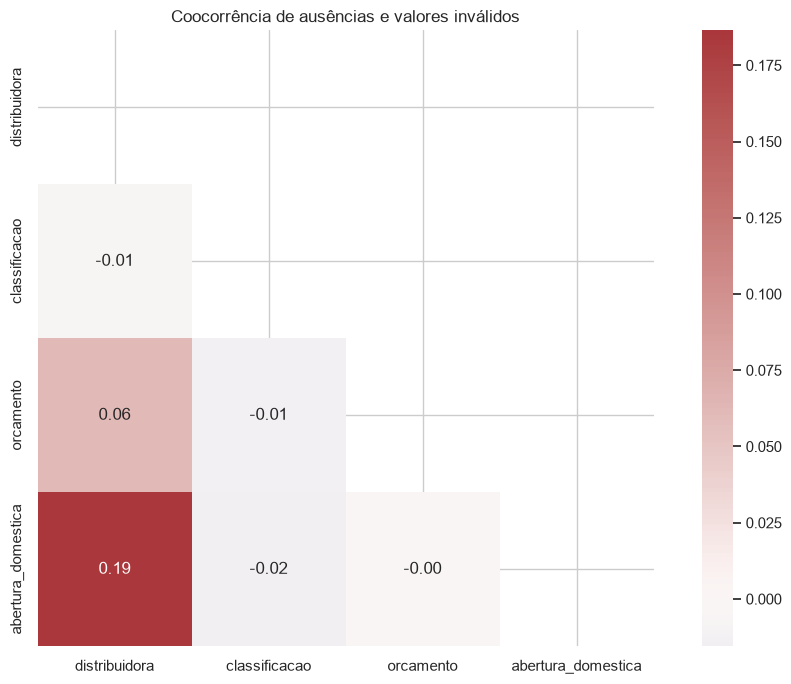

In [12]:
matriz_ausencia = df[colunas_com_ausentes].isna().astype(int)

if matriz_ausencia.shape[1] >= 2:
    correlacao_ausencias = matriz_ausencia.corr()
    mascara = np.triu(np.ones_like(correlacao_ausencias, dtype=bool))
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        correlacao_ausencias,
        mask=mascara,
        cmap="vlag",
        center=0,
        annot=True,
        fmt=".2f",
        square=True,
    )
    plt.title("Coocorrência de ausências e valores inválidos")
    plt.tight_layout()
    plt.show()
else:
    print("Há menos de duas colunas com ausências; a correlação não é aplicável.")

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

> **Adaptação para o dataset de filmes**
>
> **Modificação:** MCAR, MAR e MNAR continuam como estrutura conceitual, mas os exemplos clínicos não são usados para concluir o mecanismo dos filmes.
>
> **Por quê:** Sem documentação do processo de coleta, classificar definitivamente o mecanismo seria especulativo.
>
> **Resposta à discussão:** O padrão observado **não mostra uma concentração conjunta forte**: por exemplo, somente 6 dos 215 orçamentos ausentes coincidem com abertura ausente, e a correlação desses indicadores é aproximadamente 0. Isso sugere eventos majoritariamente distintos, mas **não prova MCAR**. Sem documentação da coleta, orçamento não divulgado e falhas de raspagem podem depender do filme ou da fonte, sendo mais prudente registrar o mecanismo como indeterminado, possivelmente MAR/MNAR.

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Os exemplos originais permanecem visíveis. Para esta base, possíveis causas são fonte sem orçamento publicado, classificação ausente e falha de parsing.
>
> **Por quê:** A adaptação separa ausência substantiva de valor inválido criado durante a conversão.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A análise usa todas as colunas com ausência para evitar uma conclusão baseada em um recorte de duas variáveis.
>
> **Por quê:** O dataset de filmes apresenta mais de um padrão relevante de incompletude.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [13]:
VARS_QUANT = [
    "ano",
    "orcamento",
    "bilheteria_domestica",
    "bilheteria_internacional",
    "bilheteria_mundial",
    "duracao_min",
]
VARS_QUALI = ["classificacao", "genero_principal", "distribuidora", "decada"]
VARS_POR_GRUPO = [
    "orcamento",
    "bilheteria_domestica",
    "bilheteria_internacional",
    "duracao_min",
]
VARS_CORR = [
    "orcamento",
    "bilheteria_domestica",
    "bilheteria_internacional",
    "bilheteria_mundial",
]

df[VARS_QUANT].describe().T

,count,mean,std,min,25%,50%,75%,max
ano,1000.0,2.008181e+03,1.058585e+01,1937.0,2002.0,2010.0,2.016000e+03,2.023000e+03
orcamento,785.0,9.742392e+07,6.069353e+07,15000.0,50000000.0,85000000.0,1.400000e+08,3.560000e+08
bilheteria_domestica,1000.0,1.646405e+08,1.197541e+08,6752.0,95725056.0,134916907.5,1.983993e+08,9.366622e+08
bilheteria_internacional,1000.0,2.640890e+08,2.133847e+08,24500000.0,132118998.0,194107663.0,3.188993e+08,2.138484e+09
bilheteria_mundial,1000.0,4.228430e+08,3.054844e+08,179968873.0,227289939.5,319714782.0,4.852363e+08,2.923706e+09
duracao_min,1000.0,1.180620e+02,2.109866e+01,72.0,102.0,116.0,1.310000e+02,2.010000e+02


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Assimetria e curtose são avaliadas nas variáveis de receita, orçamento, duração e ano.
>
> **Por quê:** Valores monetários de blockbusters costumam ter cauda à direita; por isso, os gráficos financeiros usam escala logarítmica quando apropriado.
>
> **Resposta à discussão:** As maiores assimetrias aparecem em **bilheteria doméstica (2,240)**, **internacional (2,914)** e **mundial (2,928)**. Essas três também têm caudas pesadas, com curtoses de **7,653**, **14,342** e **13,427**. O ano tem assimetria negativa de **−1,526** e curtose **5,309**, reflexo da concentração de filmes recentes e de poucos títulos antigos. Orçamento (0,749) e duração (0,657) não ultrapassam skewness 1. O padrão financeiro é coerente com poucos blockbusters muito acima dos demais.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

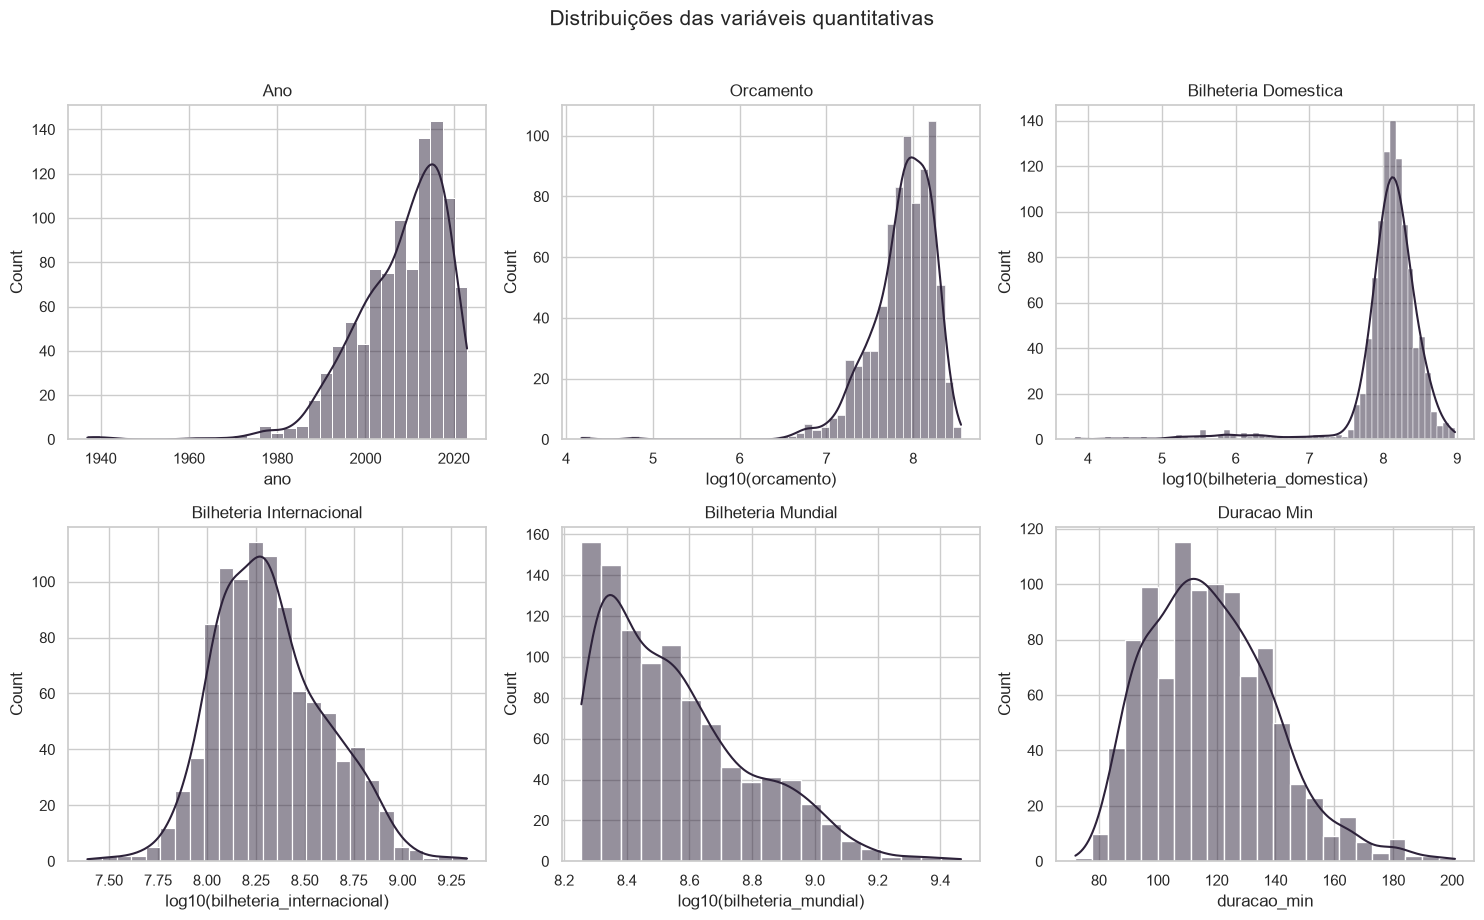

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, coluna in zip(axes.flat, VARS_QUANT):
    serie = df[coluna].dropna()
    if coluna in {"orcamento", "bilheteria_domestica", "bilheteria_internacional", "bilheteria_mundial"}:
        serie = np.log10(serie[serie > 0])
        eixo_x = f"log10({coluna})"
    else:
        eixo_x = coluna
    sns.histplot(serie, kde=True, color=COR_DESTAQUE, ax=ax)
    ax.set_title(coluna.replace("_", " ").title())
    ax.set_xlabel(eixo_x)

fig.suptitle("Distribuições das variáveis quantitativas", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

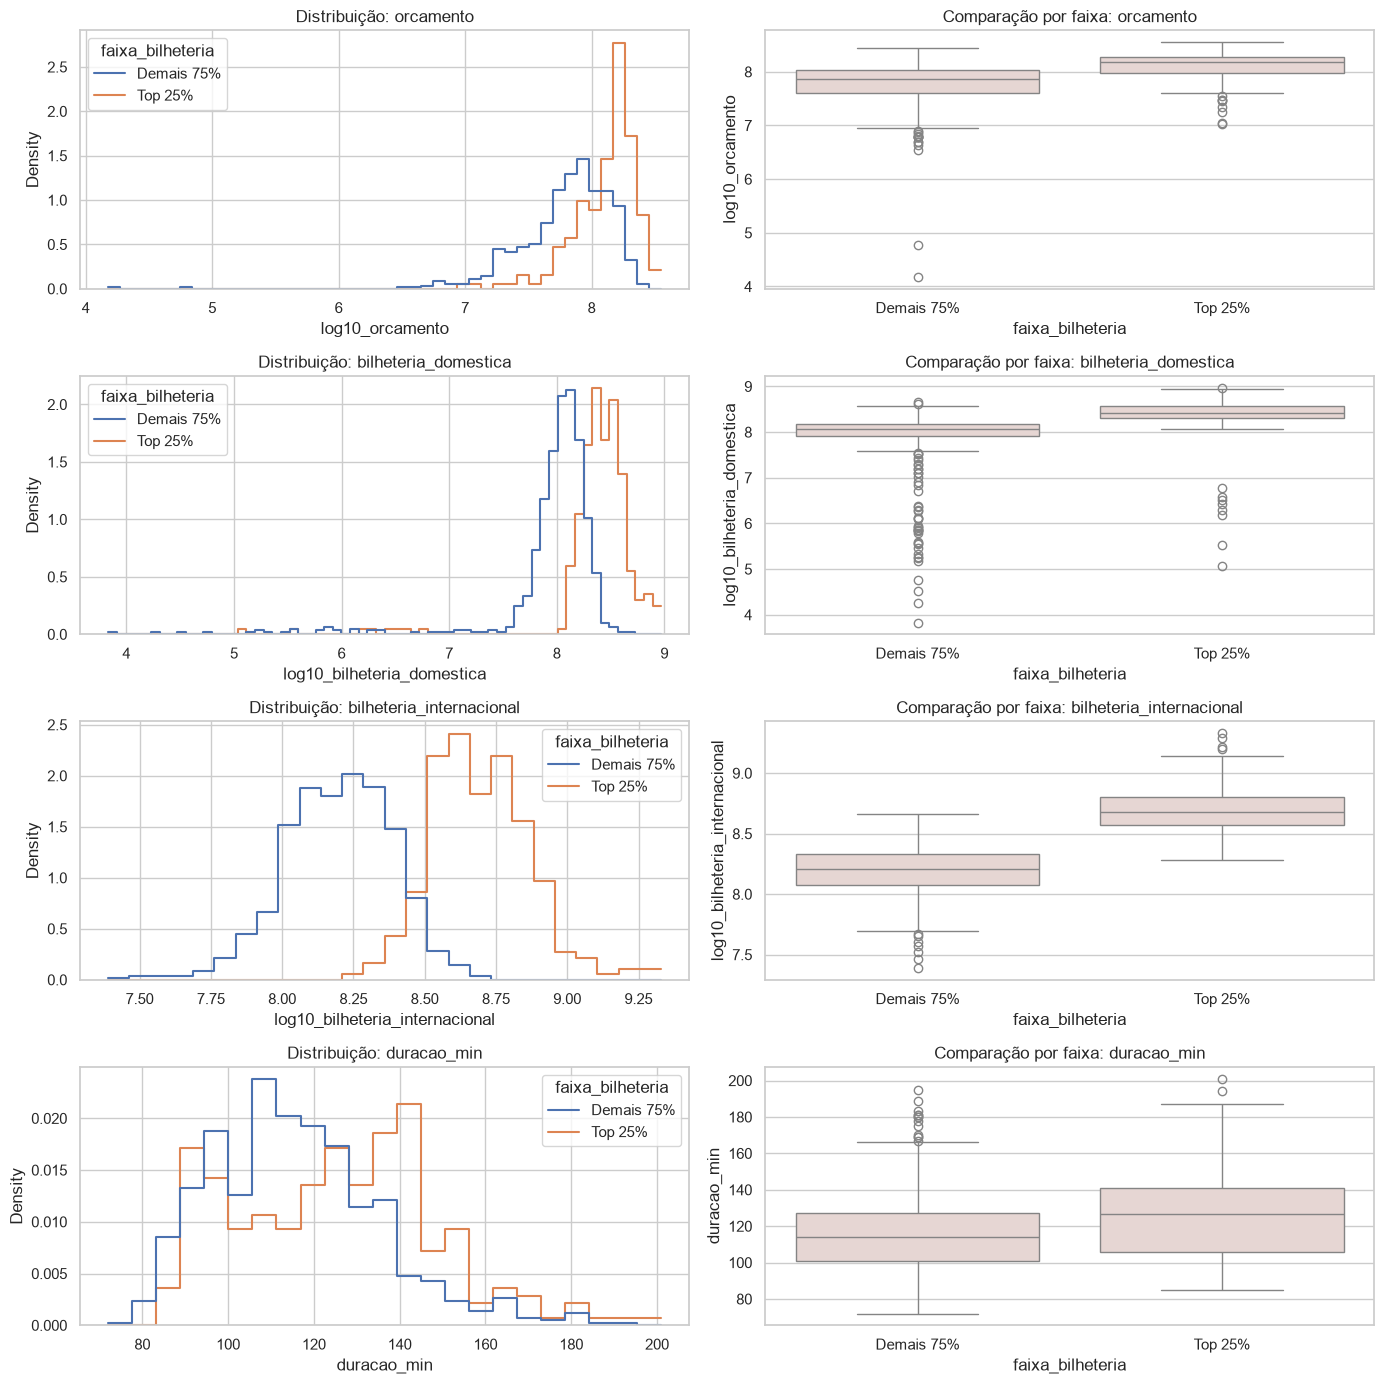

In [15]:
fig, axes = plt.subplots(len(VARS_POR_GRUPO), 2, figsize=(14, 14))

for linha, coluna in enumerate(VARS_POR_GRUPO):
    dados_plot = df[[coluna, "faixa_bilheteria"]].dropna().copy()
    valor_plot = coluna
    if coluna != "duracao_min":
        dados_plot = dados_plot[dados_plot[coluna] > 0]
        valor_plot = f"log10_{coluna}"
        dados_plot[valor_plot] = np.log10(dados_plot[coluna])

    sns.histplot(
        data=dados_plot,
        x=valor_plot,
        hue="faixa_bilheteria",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[linha, 0],
    )
    sns.boxplot(
        data=dados_plot,
        x="faixa_bilheteria",
        y=valor_plot,
        color=COR_CONTEXTO,
        ax=axes[linha, 1],
    )
    axes[linha, 0].set_title(f"Distribuição: {coluna}")
    axes[linha, 1].set_title(f"Comparação por faixa: {coluna}")

plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A comparação `Normal` versus `Cardíaco` é substituída por `Demais 75%` versus `Top 25%` de bilheteria mundial.
>
> **Por quê:** É um agrupamento compatível com o novo domínio e permite reutilizar a lógica pedagógica de comparação entre distribuições.
>
> **Resposta à discussão:** **Sim.** As distribuições financeiras do `Top 25%` estão deslocadas para valores mais altos. As medianas são: orçamento **US$ 150 milhões contra US$ 75 milhões**, bilheteria doméstica **US$ 268,3 milhões contra US$ 116,0 milhões** e internacional **US$ 478,3 milhões contra US$ 162,2 milhões**. A duração também sobe, mas menos: **126,5 contra 114 minutos**. Ainda há sobreposição, portanto os grupos não são totalmente separados. Parte da diferença financeira é esperada porque o grupo foi definido pela própria bilheteria mundial.

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.
>
> **Resposta à discussão:** A bilheteria mundial **não segue distribuição normal**: Shapiro-Wilk `W=0,7101`, `p=2,29×10⁻³⁸`. Após `log10`, a forma melhora (`W=0,9211`), mas a normalidade ainda é rejeitada (`p=1,90×10⁻²²`). O QQ plot confirma desvios, sobretudo nas caudas.

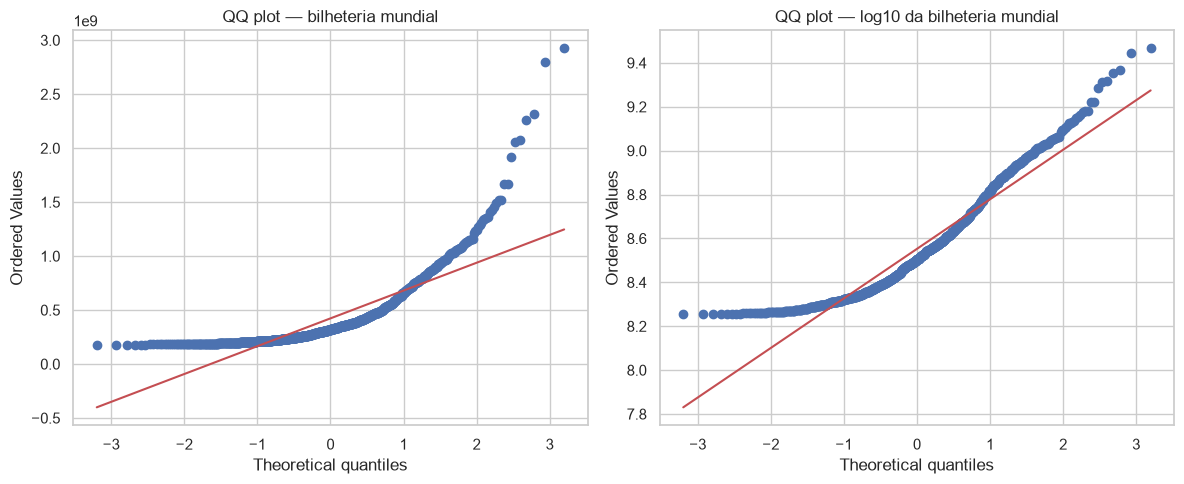

In [16]:
serie_mundial = df["bilheteria_mundial"].dropna()
serie_mundial_log = np.log10(serie_mundial[serie_mundial > 0])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
stats.probplot(serie_mundial, dist="norm", plot=axes[0])
axes[0].set_title("QQ plot — bilheteria mundial")
stats.probplot(serie_mundial_log, dist="norm", plot=axes[1])
axes[1].set_title("QQ plot — log10 da bilheteria mundial")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O teste de Shapiro-Wilk e o QQ plot são aplicados à bilheteria mundial bruta e à sua transformação log10.
>
> **Por quê:** A comparação mostra se a transformação reduz a assimetria, sem assumir normalidade apenas pela aparência do histograma.

In [17]:
resultados_shapiro = []
for nome, serie in {
    "bilheteria_mundial": serie_mundial,
    "log10_bilheteria_mundial": serie_mundial_log,
}.items():
    estatistica, p_valor = stats.shapiro(serie)
    resultados_shapiro.append({
        "variavel": nome,
        "W": estatistica,
        "p_valor": p_valor,
        "rejeita_normalidade_5pct": p_valor < 0.05,
    })

pd.DataFrame(resultados_shapiro).style.format({"W": "{:.4f}", "p_valor": "{:.3e}"})

,variavel,W,p_valor,rejeita_normalidade_5pct
0,bilheteria_mundial,0.7101,2.295e-38,True
1,log10_bilheteria_mundial,0.9211,1.897e-22,True


> **Adaptação para o dataset de filmes**
>
> **Modificação:** O markdown original acima está vazio; ele foi mantido literalmente e esta nota registra que não há conteúdo conceitual a adaptar.
>
> **Por quê:** Isso preserva também a estrutura original do notebook.

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O texto original é preservado como referência didática; exemplos e resultados do código subsequente são reinterpretados para filmes.
>
> **Por quê:** Isso mantém o roteiro original auditável e sinaliza claramente onde o contexto de cinema substitui o contexto clínico.

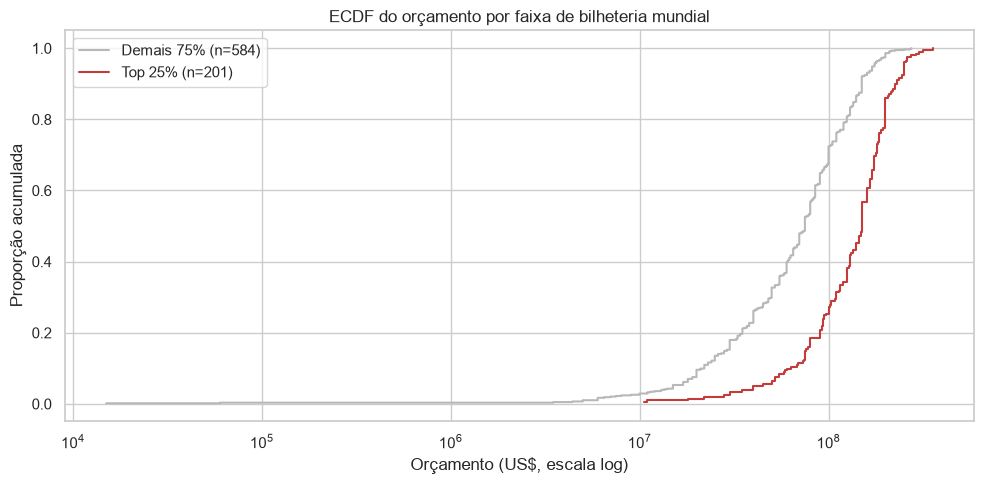

In [18]:
plt.figure(figsize=(10, 5))
for grupo, cor in [("Demais 75%", COR_NEUTRA), ("Top 25%", COR_ALERTA)]:
    serie = df.loc[df["faixa_bilheteria"] == grupo, "orcamento"].dropna()
    serie = np.sort(serie[serie > 0])
    if len(serie):
        ecdf = np.arange(1, len(serie) + 1) / len(serie)
        plt.step(serie, ecdf, where="post", label=f"{grupo} (n={len(serie)})", color=cor)

plt.xscale("log")
plt.xlabel("Orçamento (US$, escala log)")
plt.ylabel("Proporção acumulada")
plt.title("ECDF do orçamento por faixa de bilheteria mundial")
plt.legend()
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A ECDF passa a comparar a distribuição de orçamento entre as duas faixas de bilheteria.
>
> **Por quê:** Orçamento é uma medida quantitativa relevante para investigar diferenças entre filmes de maior e menor arrecadação dentro da amostra.

### Métricas de Tendêncial Central

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

Média:   US$ 422,843,049
Mediana: US$ 319,714,782
Razão média/mediana: 1.32


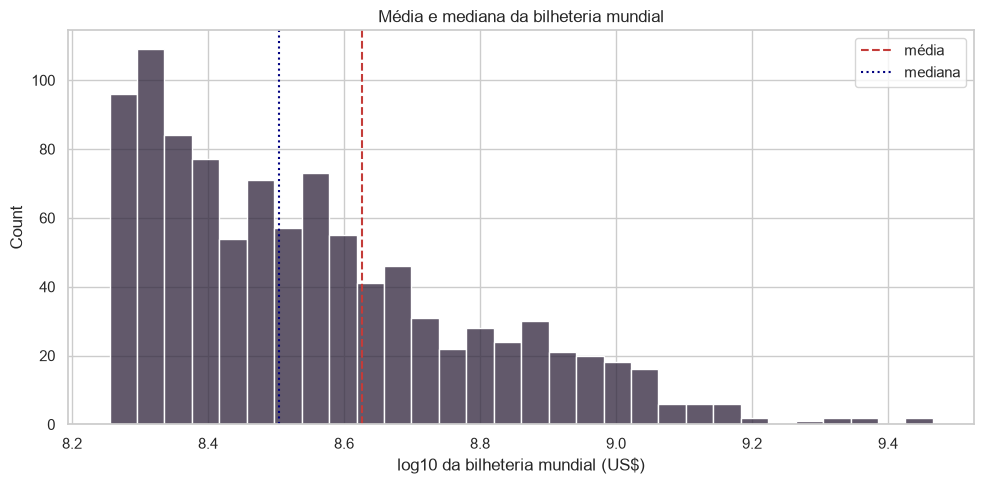

In [19]:
media_mundial = df["bilheteria_mundial"].mean()
mediana_mundial = df["bilheteria_mundial"].median()

print(f"Média:   US$ {media_mundial:,.0f}")
print(f"Mediana: US$ {mediana_mundial:,.0f}")
print(f"Razão média/mediana: {media_mundial / mediana_mundial:.2f}")

plt.figure(figsize=(10, 5))
sns.histplot(np.log10(df.loc[df["bilheteria_mundial"] > 0, "bilheteria_mundial"]), bins=30, color=COR_DESTAQUE)
plt.axvline(np.log10(media_mundial), color=COR_ALERTA, linestyle="--", label="média")
plt.axvline(np.log10(mediana_mundial), color="navy", linestyle=":", label="mediana")
plt.xlabel("log10 da bilheteria mundial (US$)")
plt.title("Média e mediana da bilheteria mundial")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

,std,var,min,max,amplitude
ano,1.058585e+01,1.120603e+02,1937.0,2.023000e+03,8.600000e+01
orcamento,6.069353e+07,3.683705e+15,15000.0,3.560000e+08,3.559850e+08
bilheteria_domestica,1.197541e+08,1.434104e+16,6752.0,9.366622e+08,9.366555e+08
bilheteria_internacional,2.133847e+08,4.553305e+16,24500000.0,2.138484e+09,2.113984e+09
bilheteria_mundial,3.054844e+08,9.332072e+16,179968873.0,2.923706e+09,2.743737e+09
duracao_min,2.109866e+01,4.451533e+02,72.0,2.010000e+02,1.290000e+02


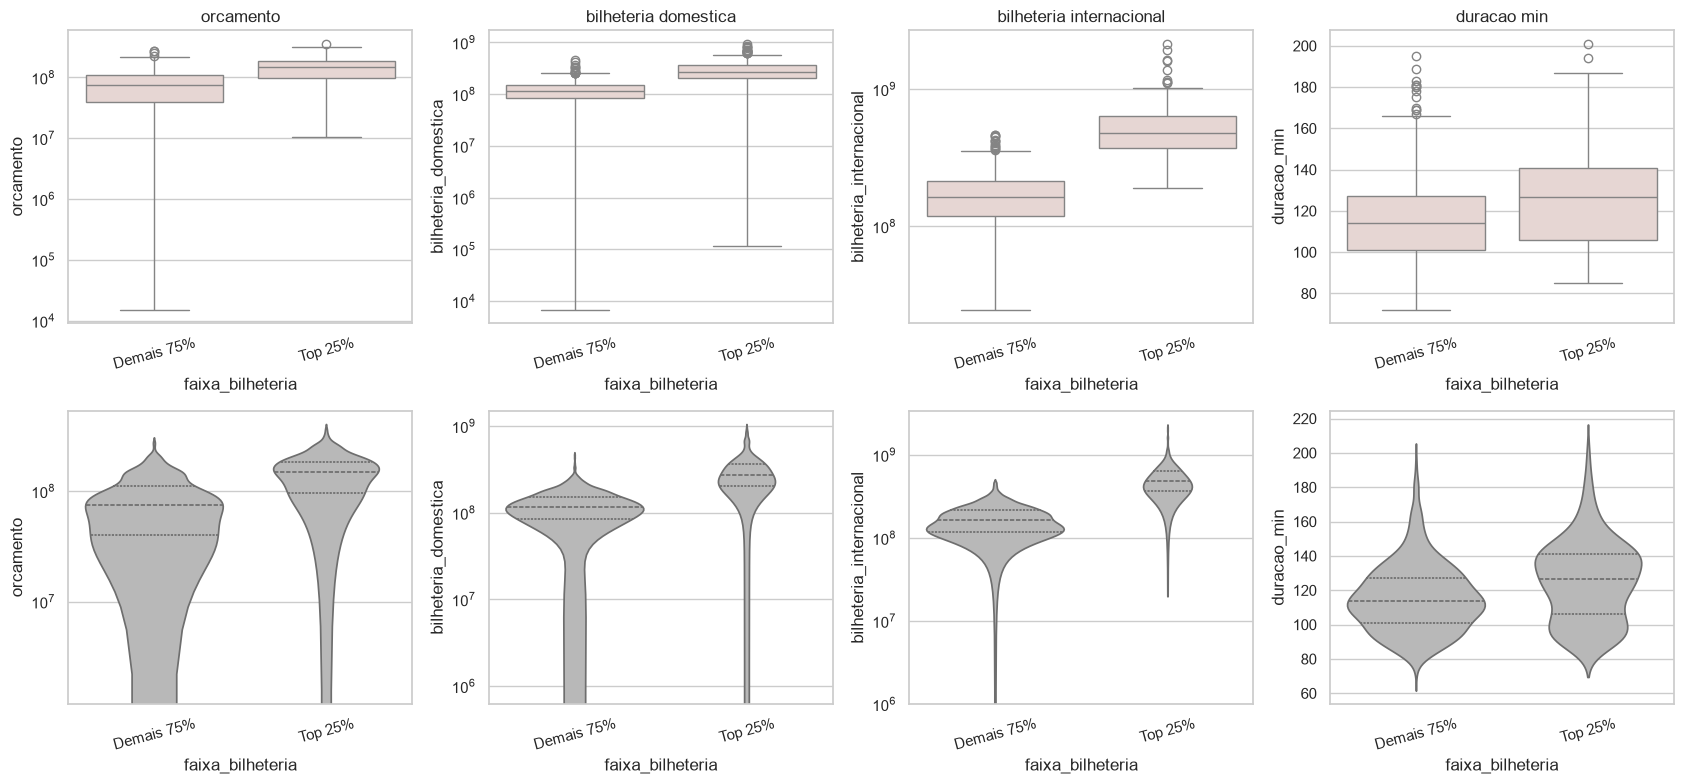

In [20]:
dispersao = df[VARS_QUANT].agg(["std", "var", "min", "max"]).T
dispersao["amplitude"] = dispersao["max"] - dispersao["min"]
display(dispersao)

fig, axes = plt.subplots(2, len(VARS_POR_GRUPO), figsize=(17, 8))
for indice, coluna in enumerate(VARS_POR_GRUPO):
    dados_plot = df[[coluna, "faixa_bilheteria"]].dropna()
    sns.boxplot(data=dados_plot, x="faixa_bilheteria", y=coluna, color=COR_CONTEXTO, ax=axes[0, indice])
    sns.violinplot(data=dados_plot, x="faixa_bilheteria", y=coluna, color=COR_NEUTRA, inner="quart", ax=axes[1, indice])
    if coluna != "duracao_min":
        axes[0, indice].set_yscale("log")
        axes[1, indice].set_yscale("log")
    axes[0, indice].set_title(coluna.replace("_", " "))
    axes[0, indice].tick_params(axis="x", rotation=15)
    axes[1, indice].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Boxplots e violin plots comparam variáveis financeiras e duração por faixa de bilheteria.
>
> **Por quê:** A escala logarítmica mantém valores extremos visíveis sem achatar a maior parte dos filmes.
>
> **Resposta à discussão:** As caixas do `Top 25%` ficam nitidamente acima nas três variáveis financeiras. O IQR do orçamento é aproximadamente **US$ 97–185 milhões** no Top 25%, contra **US$ 40–110 milhões** nos demais. Para duração, a separação é menor: IQR de **106–141** contra **101–127 minutos**. Isso indica associação descritiva, não capacidade causal ou preditiva comprovada; receitas doméstica e internacional também compõem a variável usada para formar os grupos.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [21]:
resumo_outliers = []
for coluna in VARS_QUANT:
    serie = df[coluna].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara_outlier = (serie < limite_inferior) | (serie > limite_superior)
    resumo_outliers.append({
        "variavel": coluna,
        "n_validos": len(serie),
        "outliers_iqr": int(mascara_outlier.sum()),
        "percentual": 100 * mascara_outlier.mean(),
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
    })

pd.DataFrame(resumo_outliers).style.format({"percentual": "{:.1f}%"})

,variavel,n_validos,outliers_iqr,percentual,limite_inferior,limite_superior
0,ano,1000,16,1.6%,1981.000000,2037.000000
1,orcamento,785,4,0.5%,-85000000.000000,275000000.000000
2,bilheteria_domestica,1000,71,7.1%,-58286284.500000,352410623.500000
3,bilheteria_internacional,1000,76,7.6%,-148051492.125000,599069814.875000
4,bilheteria_mundial,1000,81,8.1%,-159629555.500000,872155764.500000
5,duracao_min,1000,16,1.6%,58.500000,174.500000


### Visualizando os Outliers

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

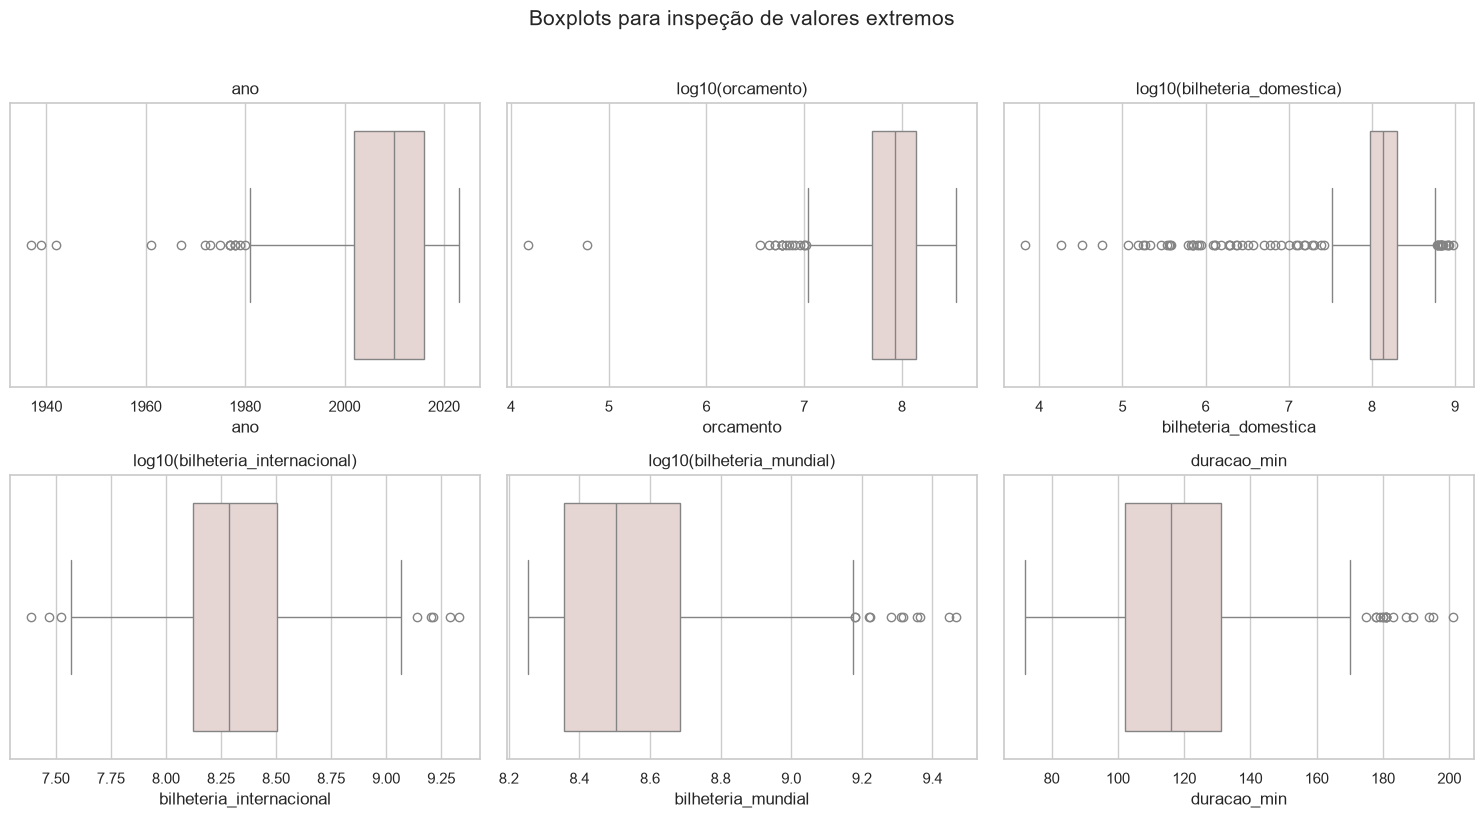

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(axes.flat, VARS_QUANT):
    serie = df[coluna].dropna()
    rotulo = coluna
    if coluna in {"orcamento", "bilheteria_domestica", "bilheteria_internacional", "bilheteria_mundial"}:
        serie = np.log10(serie[serie > 0])
        rotulo = f"log10({coluna})"
    sns.boxplot(x=serie, color=COR_CONTEXTO, ax=ax)
    ax.set_title(rotulo)

fig.suptitle("Boxplots para inspeção de valores extremos", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Valores extremos de bilheteria e orçamento não são removidos automaticamente.
>
> **Por quê:** Nesta base selecionada pelos maiores faturamentos, extremos podem ser blockbusters reais e fazem parte do fenômeno estudado.
>
> **Resposta à discussão:** O IQR sinaliza **4 orçamentos**, **71 bilheterias domésticas**, **76 internacionais**, **81 mundiais**, **16 durações** e **16 anos** como extremos. A maior bilheteria mundial é **US$ 2,924 bilhões**, compatível com um blockbuster, e o orçamento mínimo é **US$ 15 mil**, possível em um sucesso de baixo orçamento. Esses valores são raros, mas plausíveis no domínio; por isso foram mantidos. Eles só deveriam ser corrigidos ou removidos após confirmação em fonte externa de que representam erro.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Ausências categóricas são marcadas como `Não informado`; ausências numéricas permanecem `NaN`.
>
> **Por quê:** Isso evita perder filmes e, ao mesmo tempo, evita inventar orçamento, abertura ou duração.

In [23]:
linhas_antes = len(df)

for coluna in ["classificacao", "genero_principal", "distribuidora"]:
    df[coluna] = df[coluna].fillna("Não informado")

linhas_depois = len(df)
print(f"Linhas antes: {linhas_antes:,}")
print(f"Linhas depois: {linhas_depois:,}")
print("Ausências categóricas foram explicitadas como 'Não informado'.")
print("Valores numéricos inválidos permaneceram como NaN para não inventar medidas.")

Linhas antes: 1,000
Linhas depois: 1,000
Ausências categóricas foram explicitadas como 'Não informado'.
Valores numéricos inválidos permaneceram como NaN para não inventar medidas.


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Em vez de excluir outliers pelo IQR, cria-se uma versão log10 da bilheteria mundial.
>
> **Por quê:** A transformação melhora a leitura da distribuição e preserva filmes legítimos de arrecadação muito alta.

In [24]:
df["bilheteria_mundial_log"] = np.log10(df["bilheteria_mundial"].where(df["bilheteria_mundial"] > 0))

print("Os filmes não foram removidos pelo critério IQR: valores extremos podem representar blockbusters legítimos.")
print("Foi criada bilheteria_mundial_log para visualização e modelagem sensíveis à assimetria.")
df[["bilheteria_mundial", "bilheteria_mundial_log"]].head()

Os filmes não foram removidos pelo critério IQR: valores extremos podem representar blockbusters legítimos.
Foi criada bilheteria_mundial_log para visualização e modelagem sensíveis à assimetria.


,bilheteria_mundial,bilheteria_mundial_log
0,2923706026,9.465934
1,2799439100,9.447071
2,2320250281,9.365535
3,2264743305,9.355019
4,2071310218,9.316245


**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A transformação logarítmica é aplicada à bilheteria mundial, não ao colesterol.
>
> **Por quê:** Receitas são positivas e fortemente assimétricas; log10 reduz diferenças de ordem de grandeza sem remover observações.
>
> **Resposta à discussão:** **Sim, a transformação reduziu bastante a assimetria.** A skewness da bilheteria mundial cai de **2,928 para 0,909**, e a curtose de **13,427 para 0,294**. Entretanto, o Shapiro-Wilk ainda rejeita normalidade (`p≈1,90×10⁻²²`), então log10 melhora a forma, mas não torna os dados normais.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [25]:
df[VARS_QUANT + ["bilheteria_mundial_log"]].describe().T

,count,mean,std,min,25%,50%,75%,max
ano,1000.0,2.008181e+03,1.058585e+01,1.937000e+03,2.002000e+03,2.010000e+03,2.016000e+03,2.023000e+03
orcamento,785.0,9.742392e+07,6.069353e+07,1.500000e+04,5.000000e+07,8.500000e+07,1.400000e+08,3.560000e+08
bilheteria_domestica,1000.0,1.646405e+08,1.197541e+08,6.752000e+03,9.572506e+07,1.349169e+08,1.983993e+08,9.366622e+08
bilheteria_internacional,1000.0,2.640890e+08,2.133847e+08,2.450000e+07,1.321190e+08,1.941077e+08,3.188993e+08,2.138484e+09
bilheteria_mundial,1000.0,4.228430e+08,3.054844e+08,1.799689e+08,2.272899e+08,3.197148e+08,4.852363e+08,2.923706e+09
duracao_min,1000.0,1.180620e+02,2.109866e+01,7.200000e+01,1.020000e+02,1.160000e+02,1.310000e+02,2.010000e+02
bilheteria_mundial_log,1000.0,8.552431e+00,2.346789e-01,8.255197e+00,8.356580e+00,8.504763e+00,8.685953e+00,9.465934e+00


### Comparando "antes"x "depois""



> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [26]:
comparacao = pd.DataFrame({
    "antes_n": df_antes_tratamento[VARS_QUANT].count(),
    "depois_n": df[VARS_QUANT].count(),
    "antes_mediana": df_antes_tratamento[VARS_QUANT].median(),
    "depois_mediana": df[VARS_QUANT].median(),
})
comparacao["variacao_mediana_pct"] = (
    (comparacao["depois_mediana"] - comparacao["antes_mediana"])
    / comparacao["antes_mediana"].replace(0, np.nan)
    * 100
)
comparacao

,antes_n,depois_n,antes_mediana,depois_mediana,variacao_mediana_pct
ano,1000,1000,2010.0,2010.0,0.0
orcamento,785,785,85000000.0,85000000.0,0.0
bilheteria_domestica,1000,1000,134916907.5,134916907.5,0.0
bilheteria_internacional,1000,1000,194107663.0,194107663.0,0.0
bilheteria_mundial,1000,1000,319714782.0,319714782.0,0.0
duracao_min,1000,1000,116.0,116.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Nenhuma linha é removida nesta adaptação; por isso, contagens e medianas numéricas devem permanecer iguais.
>
> **Por quê:** O tratamento é conservador e prioriza rastreabilidade em uma base já selecionada pelos maiores faturamentos.
>
> **Resposta à discussão:** Os valores numéricos **não mudaram**: não houve remoção de linhas nem imputação de medidas, logo contagens válidas e medianas permanecem iguais antes e depois. A mudança ocorreu somente na explicitação de ausências categóricas como `Não informado` e na criação da coluna logarítmica. Esse resultado confirma que o tratamento foi conservador.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A verificação de normalidade passa do colesterol para a bilheteria mundial, antes e após log10.
>
> **Por quê:** O objetivo é avaliar o efeito da transformação sobre a forma da distribuição financeira.
>
> **Resposta à discussão:** **Sim, a normalidade continua rejeitada.** Para a bilheteria mundial original e para a versão tratada sem remoções, `W=0,7101` e `p≈2,29×10⁻³⁸`. Na versão log10, `W=0,9211` e `p≈1,90×10⁻²²`: há melhora, mas ainda existe evidência contra normalidade.

In [27]:
shapiro_comparacao = []
for nome, serie in {
    "original": df_antes_tratamento["bilheteria_mundial"].dropna(),
    "tratada_sem_remocao": df["bilheteria_mundial"].dropna(),
    "transformada_log10": df["bilheteria_mundial_log"].dropna(),
}.items():
    estatistica, p_valor = stats.shapiro(serie)
    shapiro_comparacao.append({"versao": nome, "W": estatistica, "p_valor": p_valor})

pd.DataFrame(shapiro_comparacao).style.format({"W": "{:.4f}", "p_valor": "{:.3e}"})

,versao,W,p_valor
0,original,0.7101,2.295e-38
1,tratada_sem_remocao,0.7101,2.295e-38
2,transformada_log10,0.9211,1.897e-22


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O texto original é preservado como referência didática; exemplos e resultados do código subsequente são reinterpretados para filmes.
>
> **Por quê:** Isso mantém o roteiro original auditável e sinaliza claramente onde o contexto de cinema substitui o contexto clínico.

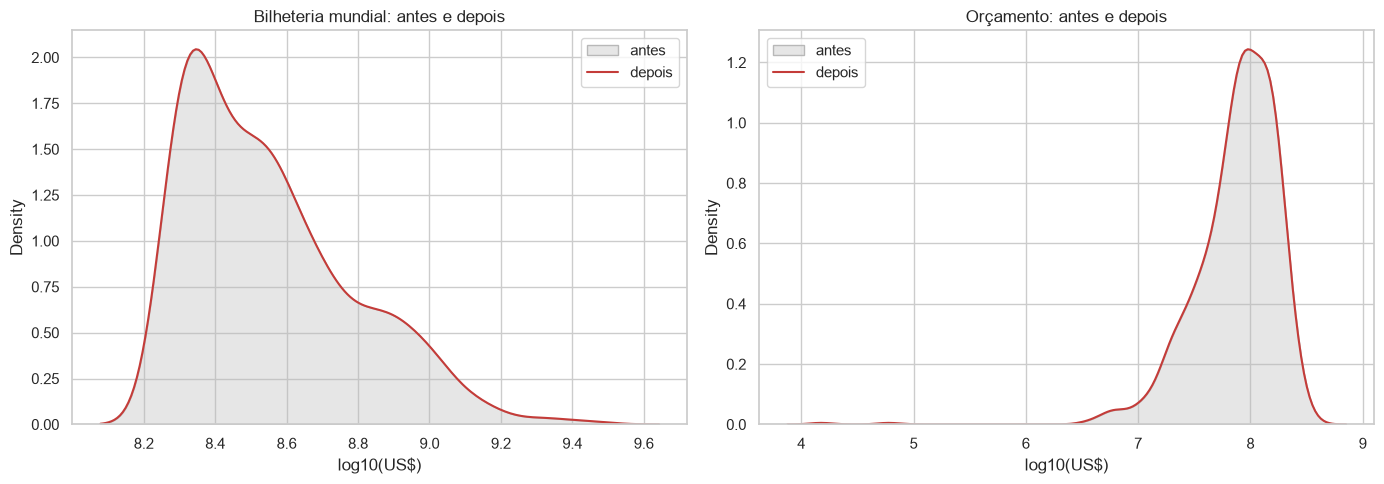

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(
    np.log10(df_antes_tratamento.loc[df_antes_tratamento["bilheteria_mundial"] > 0, "bilheteria_mundial"]),
    label="antes",
    color=COR_NEUTRA,
    fill=True,
    alpha=0.35,
    ax=axes[0],
)
sns.kdeplot(df["bilheteria_mundial_log"].dropna(), label="depois", color=COR_ALERTA, ax=axes[0])
axes[0].set_title("Bilheteria mundial: antes e depois")
axes[0].set_xlabel("log10(US$)")
axes[0].legend()

orcamento_antes = np.log10(df_antes_tratamento.loc[df_antes_tratamento["orcamento"] > 0, "orcamento"])
orcamento_depois = np.log10(df.loc[df["orcamento"] > 0, "orcamento"])
sns.kdeplot(orcamento_antes, label="antes", color=COR_NEUTRA, fill=True, alpha=0.35, ax=axes[1])
sns.kdeplot(orcamento_depois, label="depois", color=COR_ALERTA, ax=axes[1])
axes[1].set_title("Orçamento: antes e depois")
axes[1].set_xlabel("log10(US$)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A sobreposição antes/depois é esperada porque não houve exclusão; a diferença aparece na representação logarítmica.
>
> **Por quê:** Isso torna explícito que a limpeza não alterou silenciosamente a composição da amostra.
>
> **Resposta à discussão:** **Sim, as curvas antes e depois se sobrepõem.** Isso ocorre porque nenhum valor numérico foi excluído ou imputado. A sobreposição é a evidência esperada de que o tratamento não alterou silenciosamente a população analisada; a mudança visível relevante é apenas a escala log10.

## 6. Princípio Relacional

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




> **Adaptação para o dataset de filmes**
>
> **Modificação:** As variáveis qualitativas passam a ser classificação indicativa, gênero principal, distribuidora e década.
>
> **Por quê:** Elas descrevem segmentos relevantes do catálogo de filmes.

#### Frequências absolutas e relativas

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [29]:
for coluna in VARS_QUALI:
    tabela = df[coluna].value_counts(dropna=False).head(15).to_frame("frequencia")
    tabela["percentual"] = 100 * tabela["frequencia"] / len(df)
    print(f"\n{coluna.upper()}")
    display(tabela.style.format({"percentual": "{:.1f}%"}))


CLASSIFICACAO


,frequencia,percentual
classificacao,,
PG-13,486,48.6%
R,222,22.2%
PG,218,21.8%
Não informado,57,5.7%
G,17,1.7%



GENERO_PRINCIPAL


,frequencia,percentual
genero_principal,,
Action,508,50.8%
Adventure,197,19.7%
Comedy,128,12.8%
Drama,68,6.8%
Biography,39,3.9%
Horror,26,2.6%
Crime,22,2.2%
Animation,6,0.6%
Mystery,3,0.3%



DISTRIBUIDORA


,frequencia,percentual
distribuidora,,
Warner Bros.,166,16.6%
Walt Disney Studios Motion Pictures,159,15.9%
Universal Pictures,130,13.0%
Twentieth Century Fox,123,12.3%
Sony Pictures Entertainment (SPE),104,10.4%
Paramount Pictures,93,9.3%
Lionsgate,22,2.2%
DreamWorks,17,1.7%
DreamWorks Distribution,16,1.6%



DECADA


,frequencia,percentual
decada,,
2010s,453,45.3%
2000s,274,27.4%
1990s,145,14.5%
2020s,82,8.2%
1980s,31,3.1%
1970s,10,1.0%
1930s,2,0.2%
1960s,2,0.2%
1940s,1,0.1%


#### Visualizando as frequências

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

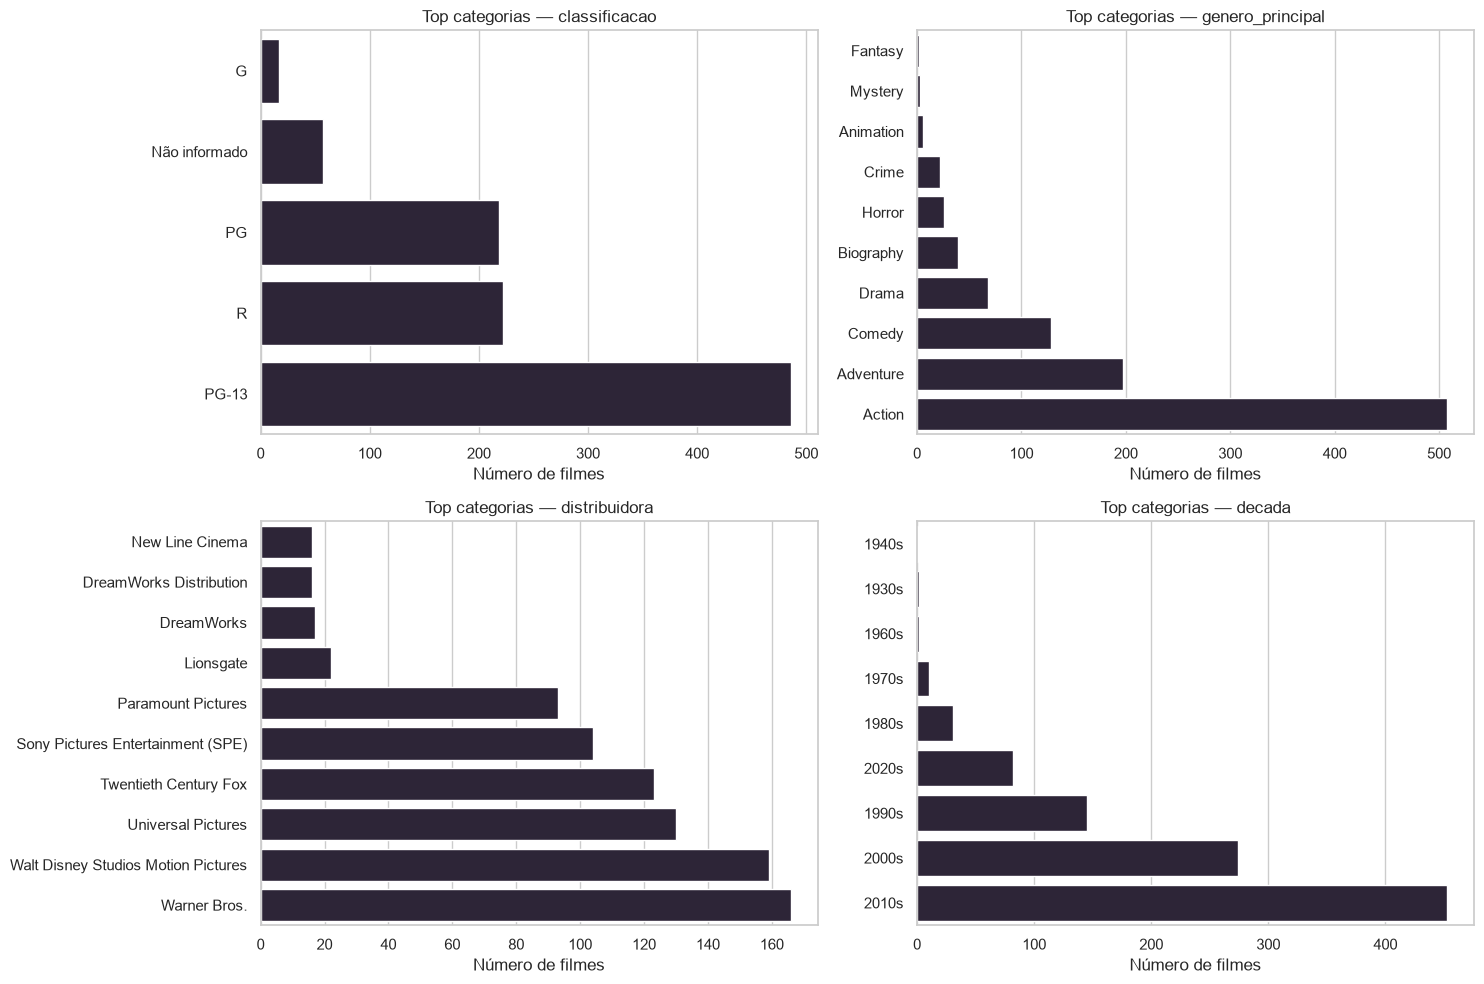

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, coluna in zip(axes.flat, VARS_QUALI):
    contagens = df[coluna].value_counts(dropna=False).head(10).sort_values()
    sns.barplot(x=contagens.values, y=contagens.index.astype(str), color=COR_DESTAQUE, ax=ax)
    ax.set_title(f"Top categorias — {coluna}")
    ax.set_xlabel("Número de filmes")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O desbalanceamento é medido nas categorias de filmes e no agrupamento de bilheteria.
>
> **Por quê:** Frequência da maior categoria e entropia normalizada quantificam concentração sem depender de um alvo médico.
>
> **Resposta à discussão:** Há concentração relevante: **Action representa 50,8%** dos gêneros principais, **PG-13 48,6%** das classificações e a década de **2010 concentra 45,3%** da amostra. A maior distribuidora, Warner Bros., responde por **16,6%**, portanto esse campo é menos dominado por uma única categoria. Categorias raras exigem cautela em cruzamentos, pois podem gerar células com frequência esperada baixa.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [31]:
metricas_desbalanceamento = []
for coluna in VARS_QUALI + ["faixa_bilheteria"]:
    proporcoes = df[coluna].value_counts(normalize=True, dropna=False)
    entropia_norm = entropy(proporcoes, base=2) / np.log2(len(proporcoes)) if len(proporcoes) > 1 else 0
    metricas_desbalanceamento.append({
        "variavel": coluna,
        "categorias": len(proporcoes),
        "maior_categoria_pct": 100 * proporcoes.iloc[0],
        "entropia_normalizada": entropia_norm,
    })

pd.DataFrame(metricas_desbalanceamento).style.format({
    "maior_categoria_pct": "{:.1f}%",
    "entropia_normalizada": "{:.3f}",
})

,variavel,categorias,maior_categoria_pct,entropia_normalizada
0,classificacao,5,48.6%,0.776
1,genero_principal,11,50.8%,0.618
2,distribuidora,72,16.6%,0.632
3,decada,9,45.3%,0.630
4,faixa_bilheteria,2,75.0%,0.811


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O alvo `doenca` do texto original não é usado. A variável `faixa_bilheteria` serve apenas para contraste descritivo.
>
> **Por quê:** O novo dataset não possui rótulo clínico ou variável de resposta originalmente definida.
>
> **Resposta à discussão:** Nenhuma variável tem entropia normalizada extremamente próxima de zero, mas gênero principal (**0,618**), década (**0,630**) e distribuidora (**0,632**) mostram concentração; classificação é mais diversa (**0,776**). `faixa_bilheteria` possui divisão **75%/25% por construção** e entropia normalizada de aproximadamente **0,811**. Portanto, não é um alvo naturalmente balanceado: um eventual modelo precisaria de divisão estratificada e métricas adequadas, além de evitar vazamento pelas receitas que definem o próprio grupo.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [32]:
correlacoes = {
    "Pearson": df[VARS_CORR].corr(method="pearson"),
    "Spearman": df[VARS_CORR].corr(method="spearman"),
    "Kendall": df[VARS_CORR].corr(method="kendall"),
}

for metodo, matriz in correlacoes.items():
    print(f"\n{metodo}")
    display(matriz.round(3))


Pearson


,orcamento,bilheteria_domestica,bilheteria_internacional,bilheteria_mundial
orcamento,1.000,0.387,0.551,0.533
bilheteria_domestica,0.387,1.000,0.693,0.839
bilheteria_internacional,0.551,0.693,1.000,0.957
bilheteria_mundial,0.533,0.839,0.957,1.000



Spearman


,orcamento,bilheteria_domestica,bilheteria_internacional,bilheteria_mundial
orcamento,1.000,0.262,0.539,0.490
bilheteria_domestica,0.262,1.000,0.463,0.720
bilheteria_internacional,0.539,0.463,1.000,0.886
bilheteria_mundial,0.490,0.720,0.886,1.000



Kendall


,orcamento,bilheteria_domestica,bilheteria_internacional,bilheteria_mundial
orcamento,1.000,0.178,0.381,0.342
bilheteria_domestica,0.178,1.000,0.311,0.543
bilheteria_internacional,0.381,0.311,1.000,0.717
bilheteria_mundial,0.342,0.543,0.717,1.000


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O texto original é preservado como referência didática; exemplos e resultados do código subsequente são reinterpretados para filmes.
>
> **Por quê:** Isso mantém o roteiro original auditável e sinaliza claramente onde o contexto de cinema substitui o contexto clínico.

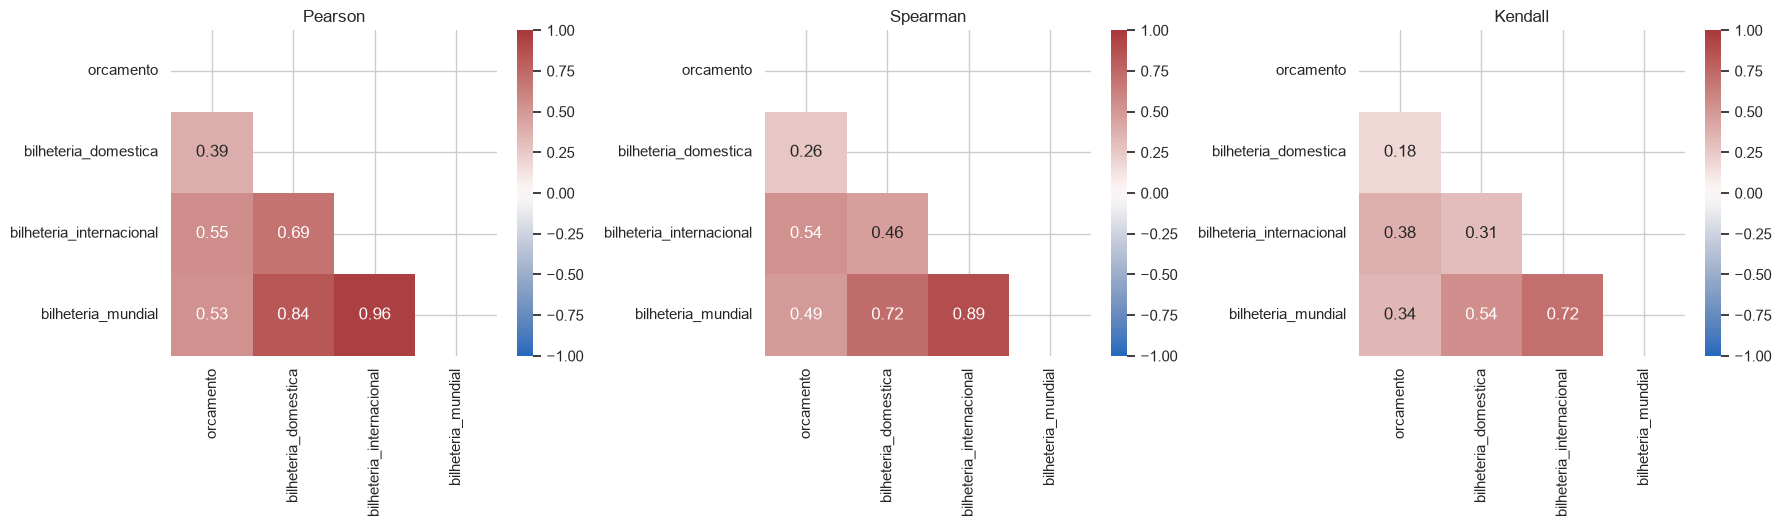

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
mascara = np.triu(np.ones((len(VARS_CORR), len(VARS_CORR)), dtype=bool))

for ax, (metodo, matriz) in zip(axes, correlacoes.items()):
    sns.heatmap(
        matriz,
        mask=mascara,
        cmap="vlag",
        center=0,
        annot=True,
        fmt=".2f",
        vmin=-1,
        vmax=1,
        square=True,
        ax=ax,
    )
    ax.set_title(metodo)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** As correlações são calculadas entre orçamento e arrecadações doméstica, internacional e mundial.
>
> **Por quê:** Spearman e Kendall complementam Pearson porque as variáveis financeiras são assimétricas e podem conter relações monotônicas não lineares.
>
> **Resposta à discussão:** A maior divergência ocorre entre bilheteria doméstica e internacional: **Pearson=0,693** e **Spearman=0,463**, diferença de 0,230. Também há diferença entre orçamento e doméstica (**0,387 contra 0,262**). Isso sugere influência de blockbusters e de relações que não são puramente lineares; não significa que Spearman revele sozinho a forma da relação.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O diagrama de dispersão compara bilheteria doméstica e internacional, colorido pela faixa de bilheteria mundial.
>
> **Por quê:** Essas duas componentes formam a receita global e permitem inspecionar dependência e valores extremos.

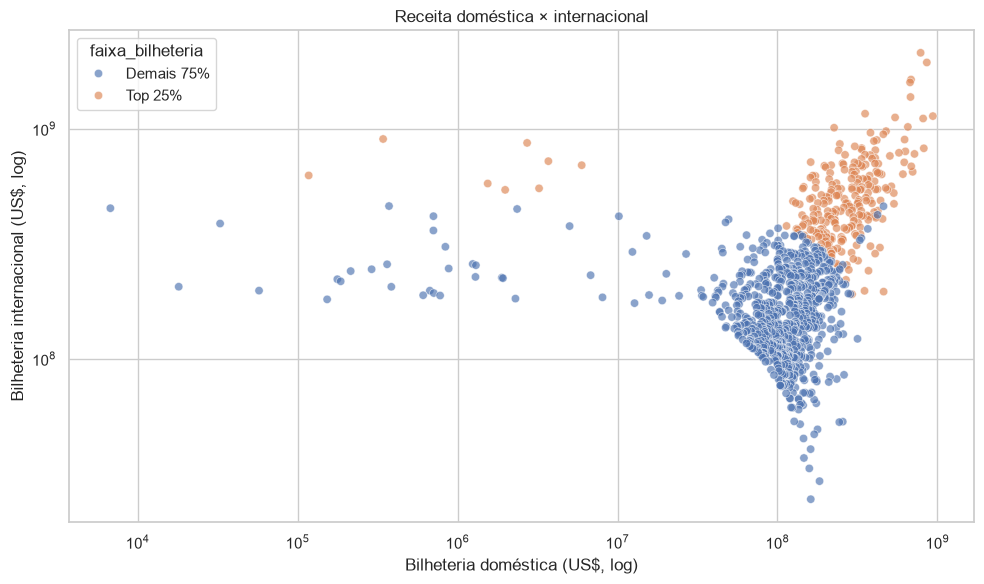

In [34]:
dados_scatter = df.query("bilheteria_domestica > 0 and bilheteria_internacional > 0").copy()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=dados_scatter,
    x="bilheteria_domestica",
    y="bilheteria_internacional",
    hue="faixa_bilheteria",
    alpha=0.65,
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Bilheteria doméstica (US$, log)")
plt.ylabel("Bilheteria internacional (US$, log)")
plt.title("Receita doméstica × internacional")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** As observações clínicas sobre idade e frequência cardíaca são substituídas pela relação entre mercados doméstico e internacional.
>
> **Por quê:** A interpretação precisa refletir composição de receita, não condição de saúde.
>
> **Resposta à discussão:** Existe uma associação positiva entre os mercados doméstico e internacional, mas com dispersão: **Spearman ρ=0,463**. Os filmes `Top 25%` aparecem principalmente na região superior/direita, embora haja mistura. Essa separação é parcialmente mecânica, pois bilheteria mundial é aproximadamente a soma das duas receitas usadas nos eixos.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Os testes entre dois grupos comparam orçamento, receitas componentes e duração entre `Top 25%` e `Demais 75%`.
>
> **Por quê:** São reportados Welch e Mann-Whitney para contrastar uma abordagem paramétrica com outra baseada em postos.

In [35]:
resultados_duas_amostras = []
for coluna in VARS_POR_GRUPO:
    grupo_top = df.loc[df["faixa_bilheteria"] == "Top 25%", coluna].dropna()
    grupo_demais = df.loc[df["faixa_bilheteria"] == "Demais 75%", coluna].dropna()

    t_stat, t_p = stats.ttest_ind(grupo_top, grupo_demais, equal_var=False)
    u_stat, u_p = stats.mannwhitneyu(grupo_top, grupo_demais, alternative="two-sided")
    resultados_duas_amostras.append({
        "variavel": coluna,
        "media_top25": grupo_top.mean(),
        "media_demais75": grupo_demais.mean(),
        "p_t_welch": t_p,
        "p_mann_whitney": u_p,
    })

pd.DataFrame(resultados_duas_amostras).style.format({
    "media_top25": "{:,.0f}",
    "media_demais75": "{:,.0f}",
    "p_t_welch": "{:.3e}",
    "p_mann_whitney": "{:.3e}",
})

,variavel,media_top25,media_demais75,p_t_welch,p_mann_whitney
0,orcamento,"145,852,736","80,755,779",1.788e-31,1.010e-34
1,bilheteria_domestica,"298,186,590","120,125,166",6.219e-48,3.288e-86
2,bilheteria_internacional,"537,940,517","172,805,156",7.366e-62,1.121e-115
3,duracao_min,125,116,1.751e-08,4.595e-09


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** ANOVA e Kruskal-Wallis avaliam bilheteria mundial entre classificações indicativas com pelo menos dez filmes.
>
> **Por quê:** O filtro reduz grupos extremamente pequenos e o teste não paramétrico é importante diante da assimetria.
>
> **Resposta à discussão:** Os testes concordam em todas as quatro variáveis: Welch e Mann-Whitney encontram diferenças com `p<0,001` para orçamento, bilheteria doméstica, internacional e duração. Os p-valores de Mann-Whitney são aproximadamente **1,01×10⁻³⁴**, **3,29×10⁻⁸⁶**, **1,12×10⁻¹¹⁵** e **4,59×10⁻⁹**, respectivamente. Mann-Whitney é o contraste principal diante da não normalidade. Ainda assim, diferenças nas receitas não devem ser tratadas como descoberta independente, porque essas receitas compõem o critério de formação do Top 25%.

In [36]:
contagem_classificacao = df["classificacao"].value_counts()
classes_validas = contagem_classificacao[contagem_classificacao >= 10].index
grupos_classificacao = [
    grupo["bilheteria_mundial"].dropna().values
    for _, grupo in df[df["classificacao"].isin(classes_validas)].groupby("classificacao", observed=True)
]

f_stat, p_anova = stats.f_oneway(*grupos_classificacao)
h_stat, p_kruskal = stats.kruskal(*grupos_classificacao)

pd.DataFrame({
    "teste": ["ANOVA", "Kruskal-Wallis"],
    "estatistica": [f_stat, h_stat],
    "p_valor": [p_anova, p_kruskal],
    "grupos": [len(grupos_classificacao)] * 2,
}).style.format({"estatistica": "{:.3f}", "p_valor": "{:.3e}"})

,teste,estatistica,p_valor,grupos
0,ANOVA,15.015,6.363e-12,5
1,Kruskal-Wallis,50.079,3.477e-10,5


**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A variável clínica `cp` é substituída por classificação indicativa.
>
> **Por quê:** Classificação possui múltiplos grupos e é adequada para ilustrar a comparação global de uma variável quantitativa.
>
> **Resposta à discussão:** **Sim, os testes concordam.** A ANOVA retorna `F=15,015`, `p=6,36×10⁻¹²`, e o Kruskal-Wallis retorna `H=50,079`, `p=3,48×10⁻¹⁰`. Ambos indicam diferença de bilheteria mundial entre pelo menos duas classificações indicativas. Kruskal-Wallis é a referência principal devido à assimetria, mas o resultado é global e não identifica quais pares diferem.

#### Qualitativa x Qualitativa

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O teste categórico passa a relacionar gênero principal e classificação indicativa.
>
> **Por quê:** Ambas são qualitativas; as categorias mais frequentes são usadas para reduzir esparsidade.

In [37]:
top_generos = df["genero_principal"].value_counts().head(8).index
top_classificacoes = df["classificacao"].value_counts().head(6).index
amostra_quiquadrado = df[
    df["genero_principal"].isin(top_generos)
    & df["classificacao"].isin(top_classificacoes)
]
tabela_contingencia = pd.crosstab(
    amostra_quiquadrado["genero_principal"],
    amostra_quiquadrado["classificacao"],
)

chi2, p_valor, graus_liberdade, esperadas = stats.chi2_contingency(tabela_contingencia)
percentual_esperadas_baixas = 100 * (esperadas < 5).mean()

display(tabela_contingencia)
print(f"Qui-quadrado: {chi2:.3f}")
print(f"Graus de liberdade: {graus_liberdade}")
print(f"p-valor: {p_valor:.3e}")
print(f"Células com frequência esperada < 5: {percentual_esperadas_baixas:.1f}%")
if percentual_esperadas_baixas > 20:
    print("Atenção: a aproximação assintótica deve ser interpretada com cautela.")

classificacao,G,Não informado,PG,PG-13,R
genero_principal,,,,,
Action,0,20,59,339,90
Adventure,16,26,135,16,4
Animation,0,2,4,0,0
Biography,0,0,2,20,17
Comedy,1,4,16,64,43
Crime,0,2,0,5,15
Drama,0,3,2,36,27
Horror,0,0,0,5,21


Qui-quadrado: 593.816
Graus de liberdade: 28
p-valor: 2.653e-107
Células com frequência esperada < 5: 42.5%
Atenção: a aproximação assintótica deve ser interpretada com cautela.


**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

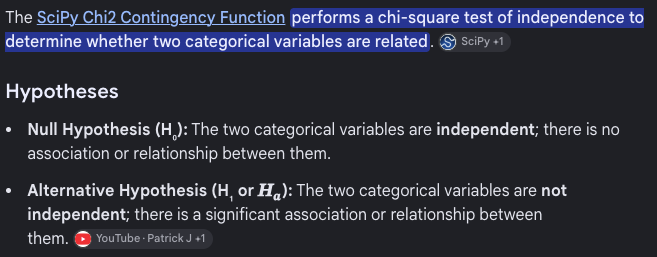

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O exemplo clínico e sua imagem permanecem intactos. O código calcula o qui-quadrado entre gênero e classificação e informa a proporção de frequências esperadas abaixo de 5.
>
> **Por quê:** Essa checagem é necessária porque tabelas esparsas podem tornar a aproximação do teste pouco confiável.
>
> **Resposta à discussão:** O teste indica associação entre gênero principal e classificação indicativa: `χ²=593,816`, `gl=28`, `p=2,65×10⁻¹⁰⁷`. Porém, **42,5% das células têm frequência esperada abaixo de 5**, acima do limite usual de 20%. Portanto, a associação parece forte, mas o p-valor assintótico deve ser interpretado com cautela; agrupar categorias raras ou usar um procedimento de Monte Carlo seria mais defensável.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A seção original de fairness é preservada, mas não é reinterpretada como auditoria de equidade para filmes.
>
> **Por quê:** O dataset não contém atributos pessoais protegidos; a adaptação analisa apenas representação e concentração por classificação e década.
>
> **Resposta à discussão:** Não é possível responder a uma pergunta de fairness pessoal com esta base, porque ela não possui pessoas, grupos protegidos nem decisões algorítmicas sobre indivíduos. A análise adaptada responde apenas sobre **representação do catálogo** por classificação e década, sem chamar diferenças comerciais de discriminação.

In [38]:
representacao = pd.DataFrame({
    "filmes": df.groupby("classificacao", observed=True).size(),
    "bilheteria_mundial_mediana": df.groupby("classificacao", observed=True)["bilheteria_mundial"].median(),
    "participacao_top25_pct": 100 * df.assign(
        top25=df["faixa_bilheteria"].eq("Top 25%")
    ).groupby("classificacao", observed=True)["top25"].mean(),
}).sort_values("filmes", ascending=False)

representacao.style.format({
    "bilheteria_mundial_mediana": "US$ {:,.0f}",
    "participacao_top25_pct": "{:.1f}%",
})

,filmes,bilheteria_mundial_mediana,participacao_top25_pct
classificacao,,,
PG-13,486,"US$ 335,368,308",30.0%
R,222,"US$ 267,608,929",7.7%
PG,218,"US$ 352,263,982",32.1%
Não informado,57,"US$ 298,572,799",8.8%
G,17,"US$ 579,330,426",70.6%


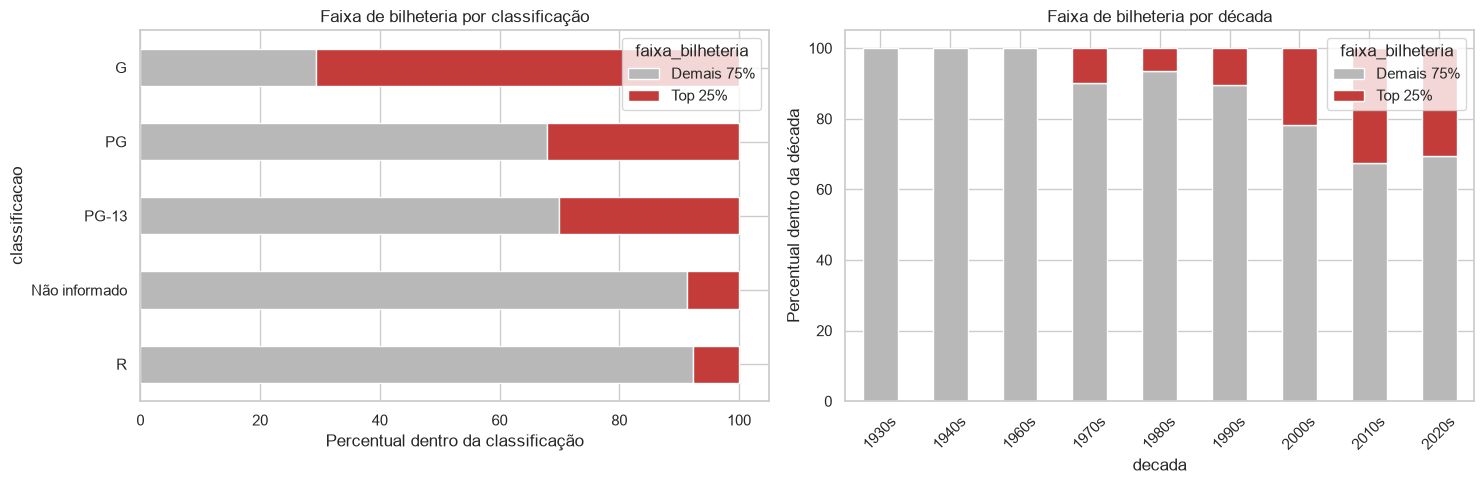

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

por_classificacao = pd.crosstab(
    df["classificacao"], df["faixa_bilheteria"], normalize="index"
).mul(100).sort_values("Top 25%")
por_classificacao.plot(kind="barh", stacked=True, color=[COR_NEUTRA, COR_ALERTA], ax=axes[0])
axes[0].set_title("Faixa de bilheteria por classificação")
axes[0].set_xlabel("Percentual dentro da classificação")

por_decada = pd.crosstab(df["decada"], df["faixa_bilheteria"], normalize="index").mul(100)
por_decada.plot(kind="bar", stacked=True, color=[COR_NEUTRA, COR_ALERTA], ax=axes[1])
axes[1].set_title("Faixa de bilheteria por década")
axes[1].set_ylabel("Percentual dentro da década")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Diferenças entre classificação, década e faixa de bilheteria são descritas como associações de catálogo.
>
> **Por quê:** Sem pessoas, decisões algorítmicas ou grupos protegidos, conclusões de justiça ou discriminação seriam inadequadas.
>
> **Resposta à discussão:** A participação no Top 25% varia: **G=70,6%**, **PG=32,1%**, **PG-13=30,0%**, **R=7,7%** e `Não informado`=8,8%. Por década, ela cresce de **6,5% nos anos 1980** e **10,3% nos 1990** para **32,5% nos 2010** e **30,5% nos 2020**. Isso não demonstra vantagem causal: a amostra contém só grandes bilheterias, valores não corrigidos pela inflação e composição temporal desigual.

In [40]:
resultados_associacao = []
for coluna in ["classificacao", "decada"]:
    tabela = pd.crosstab(df[coluna], df["faixa_bilheteria"])
    tabela = tabela.loc[tabela.sum(axis=1) >= 10]
    chi2, p_valor, graus_liberdade, esperadas = stats.chi2_contingency(tabela)
    resultados_associacao.append({
        "variavel": coluna,
        "chi2": chi2,
        "graus_liberdade": graus_liberdade,
        "p_valor": p_valor,
        "esperadas_menores_5_pct": 100 * (esperadas < 5).mean(),
    })

pd.DataFrame(resultados_associacao).style.format({
    "chi2": "{:.3f}",
    "p_valor": "{:.3e}",
    "esperadas_menores_5_pct": "{:.1f}%",
})

,variavel,chi2,graus_liberdade,p_valor,esperadas_menores_5_pct
0,classificacao,74.923,4,2.068e-15,10.0%
1,decada,39.491,5,1.891e-07,8.3%


**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Os testes de associação não estabelecem causalidade entre classificação/década e sucesso comercial.
>
> **Por quê:** A base contém somente filmes de alta bilheteria e valores nominais não corrigidos pela inflação, gerando forte viés de seleção e período.
>
> **Resposta à discussão:** **Sim, há associação estatística**: classificação × faixa de bilheteria apresenta `χ²=74,923`, `p=2,07×10⁻¹⁵`; década × faixa apresenta `χ²=39,491`, `p=1,89×10⁻⁷`. As condições de frequências esperadas são aceitáveis após o filtro de grupos com ao menos dez filmes. Os resultados mostram associação no recorte, não causalidade, fairness ou efeito isolado de classificação/década.

#### Outliers bivariados

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

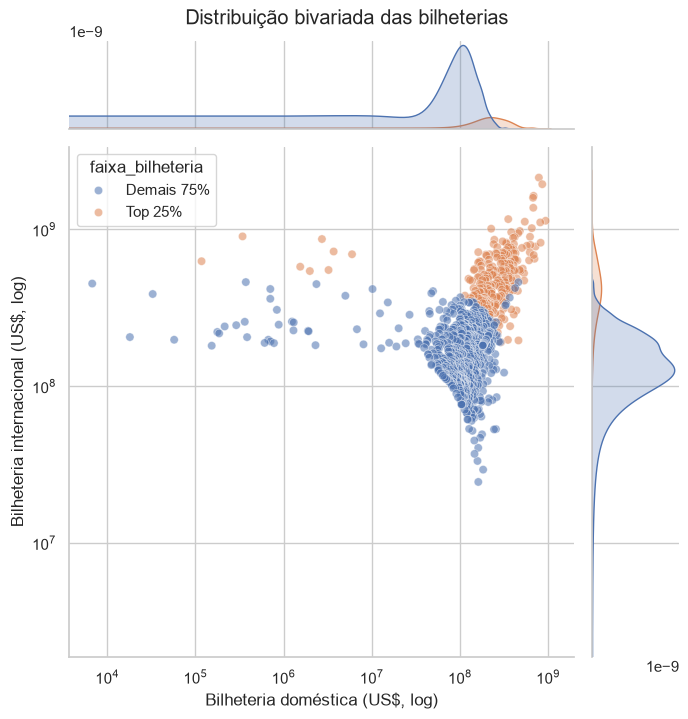

In [41]:
dados_joint = df.query("bilheteria_domestica > 0 and bilheteria_internacional > 0").copy()

grafico = sns.jointplot(
    data=dados_joint,
    x="bilheteria_domestica",
    y="bilheteria_internacional",
    hue="faixa_bilheteria",
    kind="scatter",
    height=7,
    alpha=0.55,
)
grafico.ax_joint.set_xscale("log")
grafico.ax_joint.set_yscale("log")
grafico.set_axis_labels("Bilheteria doméstica (US$, log)", "Bilheteria internacional (US$, log)")
grafico.figure.suptitle("Distribuição bivariada das bilheterias", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O jointplot usa bilheteria doméstica e internacional em escala logarítmica.
>
> **Por quê:** A visualização conjunta mostra dispersão, marginais e separação do quartil superior sem depender das variáveis clínicas originais.
>
> **Resposta à discussão:** **Sim.** `The Waterboy` é um exemplo de combinação incomum sem valores individualmente extremos pelo IQR: cerca de **US$ 161,5 milhões domésticos** e apenas **US$ 24,5 milhões internacionais**. No sentido oposto, `The Battle at Lake Changjin` tem aproximadamente **US$ 342 mil domésticos** e **US$ 902,2 milhões internacionais**. O gráfico bivariado revela desequilíbrios entre mercados que um boxplot isolado pode esconder.

#### Análise Multivariada

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de filmes.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

##### Matriz de Correlação

> **Adaptação para o dataset de filmes**
>
> **Modificação:** A matriz multivariada contém orçamento e as três medidas de arrecadação.
>
> **Por quê:** O conjunto concentra as relações financeiras centrais e evita misturar códigos categóricos como se fossem medidas contínuas.

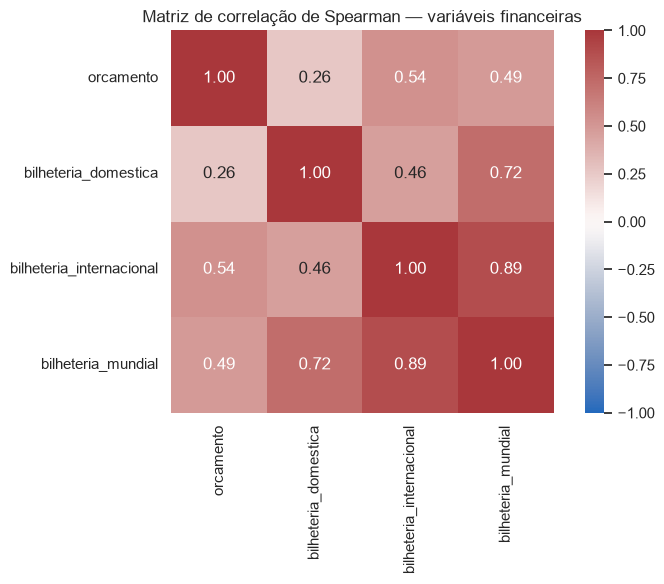

In [42]:
matriz_spearman = df[VARS_CORR].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_spearman,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
)
plt.title("Matriz de correlação de Spearman — variáveis financeiras")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

> **Adaptação para o dataset de filmes**
>
> **Modificação:** Os limiares originais permanecem como regra didática aproximada; a interpretação prioriza magnitude, direção e contexto.
>
> **Por quê:** Correlação não implica causalidade, especialmente nesta amostra selecionada de filmes campeões de bilheteria.
>
> **Resposta à discussão:** Duas correlações são fortes: bilheteria internacional × mundial (**Pearson 0,957; Spearman 0,886**) e doméstica × mundial (**0,839; 0,720**). Isso representa redundância esperada, pois a bilheteria mundial é formada pelas receitas doméstica e internacional. Em um modelo, usar simultaneamente mundial e seus componentes pode causar vazamento ou multicolinearidade. Orçamento apresenta relações apenas moderadas com receita mundial (**0,533 Pearson; 0,490 Spearman**).

##### Correlograma

> **Adaptação para o dataset de filmes**
>
> **Modificação:** O correlograma combina histogramas, dispersões e correlação de Spearman das variáveis financeiras.
>
> **Por quê:** Essa organização mantém a leitura multivariada e é mais robusta à assimetria do que usar somente Pearson.

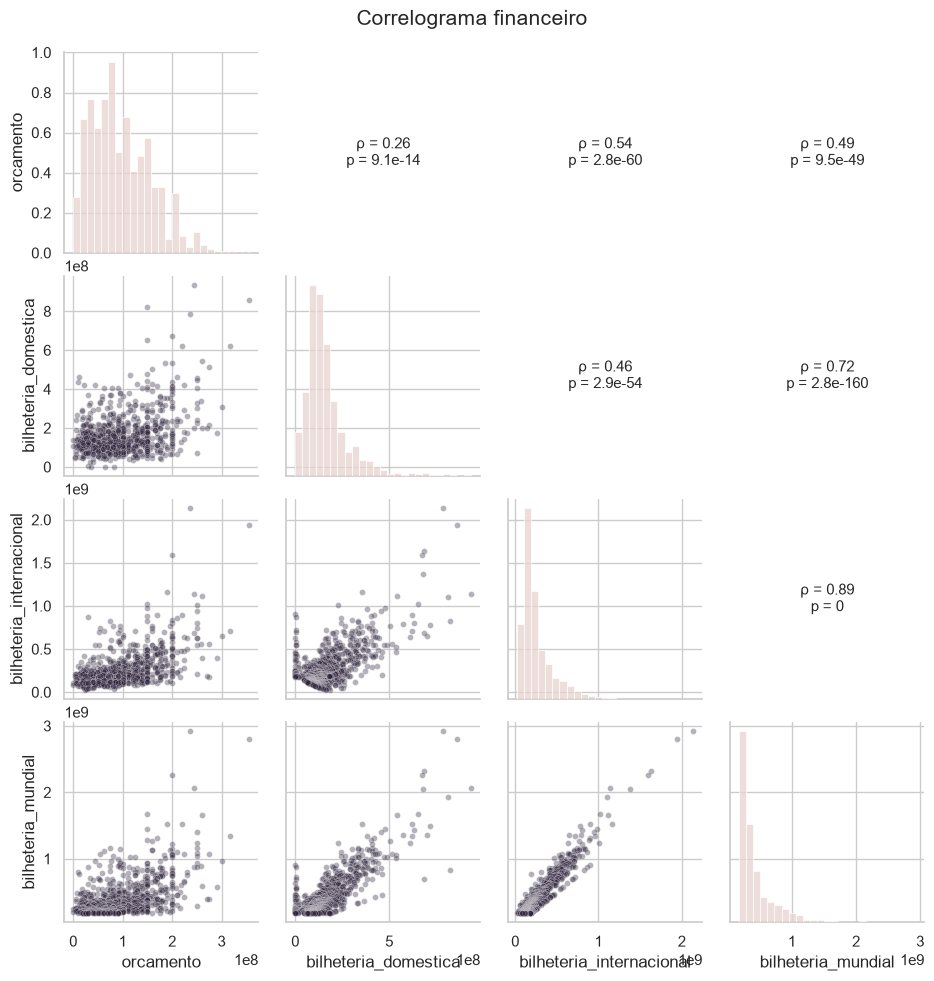

In [43]:
def correlacao_spearman(x, y, **kws):
    mascara = np.isfinite(x) & np.isfinite(y)
    if mascara.sum() < 3:
        return
    rho, p_valor = stats.spearmanr(x[mascara], y[mascara])
    ax = plt.gca()
    ax.annotate(
        f"ρ = {rho:.2f}\np = {p_valor:.2g}",
        xy=(0.5, 0.5),
        xycoords=ax.transAxes,
        ha="center",
        va="center",
        fontsize=11,
    )
    ax.set_axis_off()

dados_pairgrid = df[VARS_CORR].replace([np.inf, -np.inf], np.nan)
grade = sns.PairGrid(dados_pairgrid, diag_sharey=False, height=2.4)
grade.map_lower(sns.scatterplot, color=COR_DESTAQUE, alpha=0.35, s=18)
grade.map_diag(sns.histplot, color=COR_CONTEXTO, bins=25)
grade.map_upper(correlacao_spearman)
grade.figure.suptitle("Correlograma financeiro", y=1.02, fontsize=15)
plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




> **Adaptação para o dataset de filmes**
>
> **Modificação:** O exercício prático passa a ser uma síntese automatizada dos achados do dataset de filmes, mantendo as perguntas originais como referência.
>
> **Por quê:** A síntese final documenta qualidade, distribuição, relações e limitações com números calculados pelo próprio notebook.
>
> **Resposta à discussão:** A EDA adaptada responde às perguntas com evidências do CSV: identifica ausências e seus padrões, quantifica assimetria e outliers, compara grupos, testa associações e registra limitações. A principal conclusão é que a amostra descreve somente os 1.000 maiores faturamentos nominais; ela não representa todos os filmes e não sustenta inferências causais sobre sucesso comercial.

In [44]:
rho_dom_int, p_dom_int = stats.spearmanr(
    df["bilheteria_domestica"], df["bilheteria_internacional"], nan_policy="omit"
)
participacao_internacional = (
    df["bilheteria_internacional"] / df["bilheteria_mundial"].replace(0, np.nan)
).median()
classe_mais_comum = df["classificacao"].value_counts().idxmax()
classe_mais_comum_pct = 100 * df["classificacao"].value_counts(normalize=True).iloc[0]

print("SÍNTESE DA EDA")
print(f"• Amostra: {len(df):,} filmes, de {int(df['ano'].min())} a {int(df['ano'].max())}.")
print(f"• Bilheteria mundial mediana: US$ {df['bilheteria_mundial'].median():,.0f}.")
print(f"• Participação internacional mediana na receita mundial: {participacao_internacional:.1%}.")
print(f"• Classificação mais frequente: {classe_mais_comum} ({classe_mais_comum_pct:.1f}%).")
print(f"• Correlação de Spearman entre receitas doméstica e internacional: ρ={rho_dom_int:.2f} (p={p_dom_int:.2e}).")
print(f"• Orçamento ausente/inválido: {df['orcamento'].isna().sum()} filmes.")
print("• Limitação central: a base contém apenas filmes de alta bilheteria e valores nominais não ajustados pela inflação.")

SÍNTESE DA EDA
• Amostra: 1,000 filmes, de 1937 a 2023.
• Bilheteria mundial mediana: US$ 319,714,782.
• Participação internacional mediana na receita mundial: 60.3%.
• Classificação mais frequente: PG-13 (48.6%).
• Correlação de Spearman entre receitas doméstica e internacional: ρ=0.46 (p=2.89e-54).
• Orçamento ausente/inválido: 215 filmes.
• Limitação central: a base contém apenas filmes de alta bilheteria e valores nominais não ajustados pela inflação.


## Declaração de uso de IA

Este notebook foi adaptado com apoio de IA generativa. A IA foi utilizada para preservar e reorganizar o roteiro original, mapear variáveis do domínio clínico para o domínio cinematográfico, adaptar o código Python e apoiar a validação de execução. Os resultados quantitativos apresentados são calculados diretamente a partir do arquivo local `Highest Holywood Grossing Movies.csv`; interpretações devem considerar as limitações e o viés de seleção descritos no notebook.

---

## Exportação do dataset tratado

A célula abaixo salva o `df` no estado final da EDA em `data/clean/dataset.csv`, seguindo o padrão do notebook `eda-com-downloads.ipynb`. Esse é o arquivo consumido pelo aplicativo Streamlit.

In [ ]:
# Define a pasta de destino quando o notebook é executado da raiz ou de notebooks/
RAIZ_PROJETO = Path("..") if Path("../data").exists() else Path(".")
PASTA_CLEAN = RAIZ_PROJETO / "data" / "clean"
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [ ]:
# Exporta o dataset tratado no estado final da EDA
ARQUIVO_CLEAN = PASTA_CLEAN / "dataset.csv"
df.to_csv(ARQUIVO_CLEAN, index=False, encoding="utf-8")

print(f"Dataset tratado salvo em {ARQUIVO_CLEAN.resolve()}")
print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")